# 💰 Deep Learning Mini Project: Memprediksi Status Jutawan dari Kebiasaan & Perilaku Finansial
**Mata Kuliah**: Pembelajaran Mesin Mendalam (Deep Learning) — FMIPA Universitas Gadjah Mada
**Dataset**: *Millionaire Habits Dataset* (100.000 individu sintetis, 274 kolom) · **Target**: `millionaire_status` (klasifikasi biner)
**Framework**: Python, PyTorch, Scikit-Learn, Pandas, Matplotlib, Seaborn

---

### 🧭 Peta Notebook
| Bagian | Isi |
|:--|:--|
| 1 | Identitas & pembagian tugas |
| 2 | Problem statement & prinsip anti-*leakage* |
| 3 | Setup & reproducibility |
| 4 | EDA (target, missing value, distribusi fitur) |
| 5 | **Audit leakage** (dibuktikan dengan data) & definisi 3 set fitur |
| 6 | Split data & preprocessing |
| 7 | Arsitektur: Baseline MLP, Deep Regularized MLP, Tabular ResNet |
| 8 | Fungsi pelatihan & evaluasi |
| 9 | **Eksperimen 1** — benchmark 3 arsitektur dengan 5-fold CV → pemilihan *champion* |
| 10 | **Eksperimen 2** — hyperparameter tuning pada champion (pakai *validation*, bukan test) |
| 11 | **Eksperimen 3** — ablation: dampak kolom neraca & kolom arus uang |
| 12 | Evaluasi akhir di *test set* (dipakai **sekali**), kurva belajar, overfitting, kalibrasi |
| 13 | Interpretabilitas: permutation importance seluruh fitur |
| 14 | Fungsi inferensi |
| 15 | Kesimpulan, keterbatasan, saran lanjutan |

### 🔧 Apa yang diperbaiki dibanding draf sebelumnya?
| Masalah di draf lama | Perbaikan di notebook ini |
|:--|:--|
| Komponen aset (`stocks_value`, `investment_assets`, …) & `total_debt` masih jadi fitur → leakage terselubung | Seluruh kolom neraca, `total_debt`, dan turunan *net worth* dibuang; dampaknya **diukur** lewat ablation |
| Perbandingan model tidak adil (optimizer/scheduler berbeda) atau champion tidak sesuai hasil | Ketiga arsitektur memakai optimizer, scheduler, early stopping yang **sama**; champion dipilih otomatis dari hasil CV (aturan 1-SE) |
| Hyperparameter dipilih memakai *test set* | Tuning memakai *validation set*; *test set* hanya dipakai di evaluasi akhir |
| Kesimpulan tidak cocok dengan angka | Kesimpulan dihasilkan **dari variabel hasil eksperimen** (angka selalu sinkron) |
| Feature importance hanya 35 kolom / korelasi biasa | Permutation importance pada **semua** fitur asli (one-hot digabung per kolom) |
| Tanpa baseline klasik | Ditambah Logistic Regression & Gradient Boosting sebagai pembanding |

---
## 1. Identitas & Pembagian Tugas Kelompok

| No | Nama Mahasiswa | NIM | Peran & Deskripsi Tugas |
|:--|:--|:--|:--|
| 1 | *[Isi nama]* | *[Isi NIM]* | **Arsitektur & Model**: desain MLP, Deep Regularized MLP, Tabular ResNet; implementasi pipeline PyTorch |
| 2 | *[Isi nama]* | *[Isi NIM]* | **Data Engineering**: audit leakage, imputasi, encoding, scaling, split |
| 3 | *[Isi nama]* | *[Isi NIM]* | **Learning Strategy & Tuning**: optimizer, learning rate, regularisasi, early stopping |
| 4 | *[Isi nama]* | *[Isi NIM]* | **Evaluasi & Interpretabilitas**: CV, ablation, permutation importance, slide |

> ✏️ *Lengkapi nama & NIM sesuai anggota final kelompok.*

---
## 2. Problem Statement & Prinsip Anti-Leakage

### 📌 Pertanyaan riset
> **Apakah kebiasaan (menabung, berinvestasi, produktivitas, gaya hidup, psikologi keuangan) dapat memprediksi apakah seseorang berstatus jutawan — dan kebiasaan apa yang paling membedakan?**

Target didefinisikan secara aritmetis:

$$\text{millionaire\_status}=\mathbb{1}\left[\text{net\_worth}\ge 1.000.000\right],\qquad \text{net\_worth}=\text{total\_assets}-\text{total\_liabilities}$$

### ⚠️ Mengapa leakage harus ditangani serius
*Target leakage* terjadi bila model diberi fitur yang sudah "mengandung jawaban". Pada dataset ini ada tiga level:

1. **Leakage langsung** — `net_worth`, `net_worth_log`, `net_worth_percentile`, `wealth_bracket`, `wealth_category`, `multi_millionaire_status`, `financial_independence_status`. Semuanya turunan *net worth*.
2. **Leakage neraca** — `total_assets`, `total_liabilities`, **`total_debt`** (identik dengan `total_liabilities`) dan seluruh komponen aset/utang (`stocks_value`, `investment_assets`, `real_estate_value`, `mortgage_debt`, dst.). Mengetahui isi neraca ≈ mengetahui kekayaan, sehingga model tidak lagi "belajar dari kebiasaan".
3. **Arus uang** (pendapatan, tabungan, investasi bulanan, pengeluaran) — *bukan* leakage murni (ini bisa diketahui tanpa tahu net worth), tetapi bersifat **hasil**, bukan **kebiasaan**. Karena itu kami menyediakan set fitur "tanpa arus uang" (Set C/D) sebagai pembanding.

Bagian 5 membuktikan semua klaim ini langsung dari data, bukan hanya dari asumsi.

---
## 3. Setup & Reproducibility

In [1]:
import os, time, random, json, copy, warnings
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, classification_report, roc_curve,
                             precision_recall_curve)
import joblib

warnings.filterwarnings("ignore")

# ---------- Konfigurasi global (satu tempat untuk semua eksperimen) ----------
SEED        = 42
BATCH_SIZE  = 512
MAX_EPOCHS  = 30      # batas atas; early stopping biasanya berhenti lebih awal
PATIENCE    = 6       # early stopping pada val_loss
LR, WD      = 1e-3, 1e-4
CV_FOLDS    = 5
N_SEEDS     = 5       # untuk uji stabilitas model akhir

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)

seed_everything()
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEVICE = "cpu"   # data tabular kecil: CPU sudah cukup & deterministik

FIG_DIR, OUT_DIR = Path("figures"), Path("outputs")
FIG_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

# ---------- Tema visual konsisten ----------
C = dict(blue="#2563EB", orange="#F59E0B", green="#16A34A", red="#DC2626",
         purple="#7C3AED", gray="#6B7280", teal="#0D9488")
MODEL_COLORS = {"Baseline MLP": C["blue"], "Deep Regularized MLP": C["orange"], "Tabular ResNet": C["green"]}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

print(f"PyTorch {torch.__version__} | device: {DEVICE} | threads: {torch.get_num_threads()} | seed: {SEED}")

PyTorch 2.14.1+cu130 | device: cpu | threads: 2 | seed: 42


---
## 4. Eksplorasi Data (EDA)
Memuat dataset (mencari di beberapa lokasi umum), mengecek ukuran, distribusi target, dan kelengkapan data.

In [2]:
CANDIDATE_PATHS = ["Millionaire_Habits_Dataset.csv", "datasets/Millionaire_Habits_Dataset.csv",
                   "../Millionaire_Habits_Dataset.csv", "/mnt/user-data/uploads/Millionaire_Habits_Dataset.csv"]
data_path = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Letakkan Millionaire_Habits_Dataset.csv di folder yang sama dengan notebook.")

t0 = time.time()
df = pd.read_csv(data_path)
TARGET = "millionaire_status"
y_all = df[TARGET].values.astype(np.float32)
print(f"File     : {data_path}")
print(f"Dimensi  : {df.shape[0]:,} baris × {df.shape[1]} kolom  (dibaca {time.time()-t0:.1f} dtk)")
print(f"Numerik  : {df.select_dtypes('number').shape[1]} kolom | Non-numerik: {df.select_dtypes(exclude='number').shape[1]} kolom")

File     : Millionaire_Habits_Dataset.csv
Dimensi  : 100,000 baris × 274 kolom  (dibaca 2.0 dtk)
Numerik  : 229 kolom | Non-numerik: 45 kolom


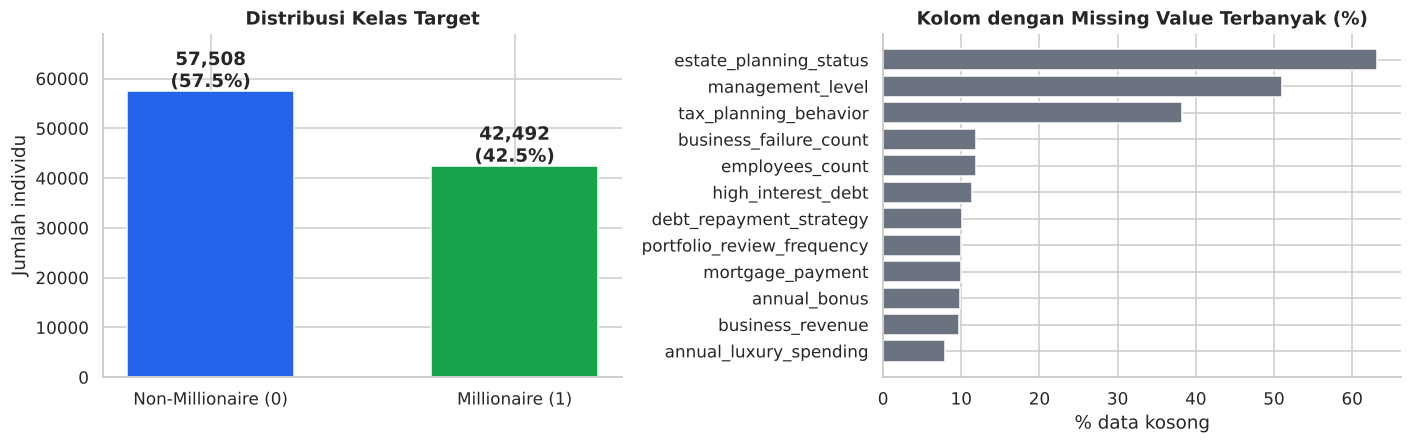

Kolom yang punya missing value: 34 dari 274
Kelas cukup seimbang (rasio ≈ 57:43) → accuracy valid dipakai, tetap dilaporkan bersama F1, ROC-AUC, PR-AUC.


In [3]:
# Distribusi kelas & kolom dengan missing value
counts = df[TARGET].value_counts().sort_index()
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0].head(12)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
bars = ax[0].bar(["Non-Millionaire (0)", "Millionaire (1)"], counts.values, color=[C["blue"], C["green"]], width=.55)
for b, v in zip(bars, counts.values):
    ax[0].text(b.get_x()+b.get_width()/2, v+800, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", fontweight="bold")
ax[0].set_title("Distribusi Kelas Target"); ax[0].set_ylabel("Jumlah individu"); ax[0].set_ylim(0, counts.max()*1.2)

ax[1].barh(miss.index[::-1], miss.values[::-1], color=C["gray"])
ax[1].set_title("Kolom dengan Missing Value Terbanyak (%)"); ax[1].set_xlabel("% data kosong")
savefig("01_target_dan_missing"); plt.show()
print(f"Kolom yang punya missing value: {int((df.isna().sum()>0).sum())} dari {df.shape[1]}")
print("Kelas cukup seimbang (rasio ≈ 57:43) → accuracy valid dipakai, tetap dilaporkan bersama F1, ROC-AUC, PR-AUC.")

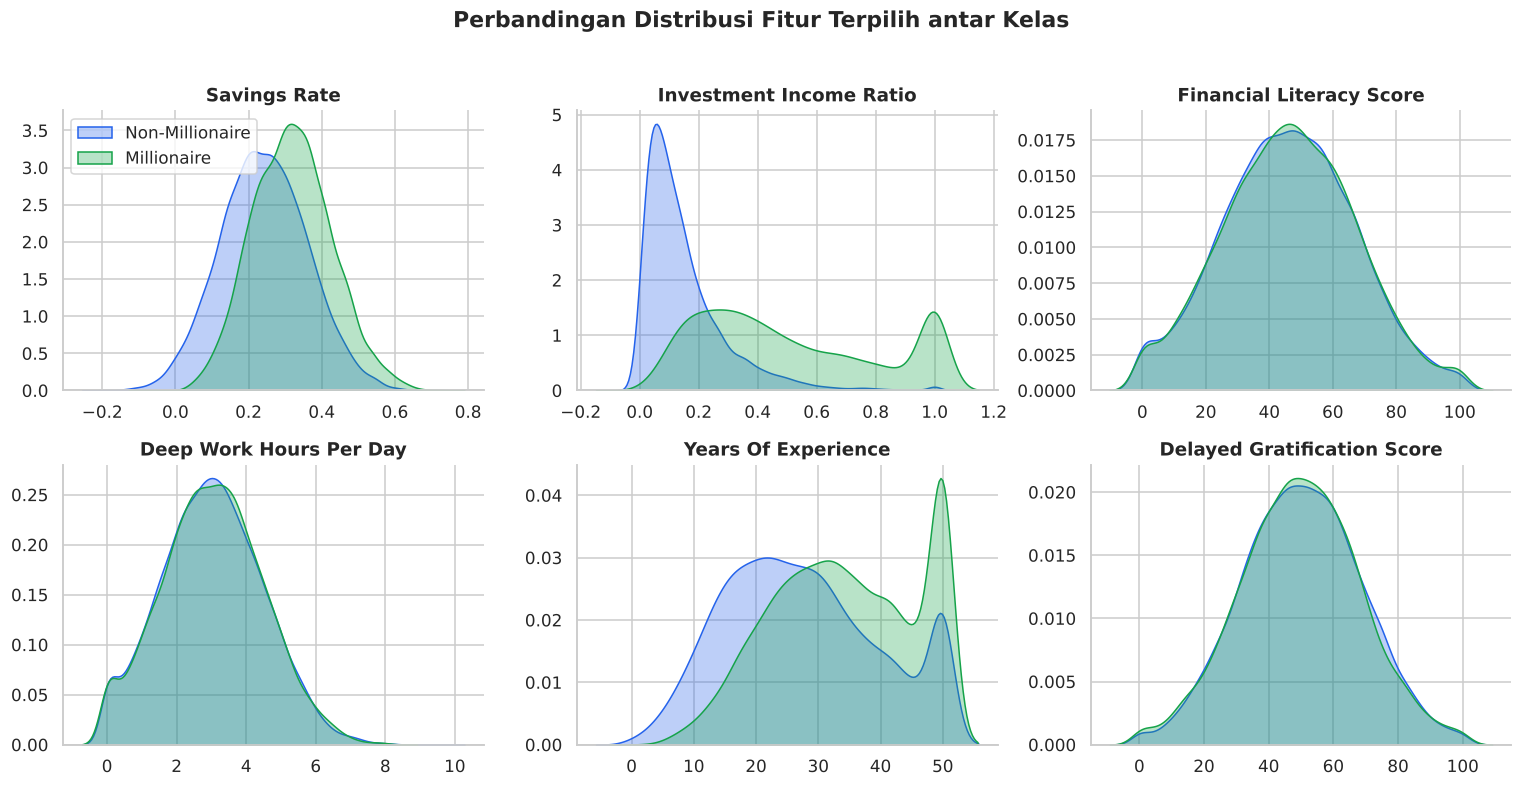

In [4]:
# Distribusi beberapa fitur 'kebiasaan' berdasarkan kelas
show = ["savings_rate", "investment_income_ratio", "financial_literacy_score",
        "deep_work_hours_per_day", "years_of_experience", "delayed_gratification_score"]
samp = df.sample(20000, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), show):
    for cls, color, lbl in [(0, C["blue"], "Non-Millionaire"), (1, C["green"], "Millionaire")]:
        sns.kdeplot(samp.loc[samp[TARGET]==cls, col].dropna(), ax=ax, color=color, fill=True, alpha=.30, label=lbl, common_norm=False)
    ax.set_title(col.replace("_", " ").title()); ax.set_xlabel(""); ax.set_ylabel("")
axes[0, 0].legend()
fig.suptitle("Perbandingan Distribusi Fitur Terpilih antar Kelas", fontweight="bold", y=1.02)
savefig("02_distribusi_fitur"); plt.show()

---
## 5. Audit Leakage & Definisi Set Fitur

Sebelum membuang kolom, kami **memverifikasi hubungan matematisnya** langsung dari data (bukan sekadar mengandalkan nama kolom).

In [5]:
BAL_ASSETS = ["cash_savings", "checking_savings", "investment_assets", "stocks_value", "bonds_value",
              "real_estate_value", "retirement_accounts", "business_equity", "alternative_assets",
              "vehicle_assets", "other_assets"]
BAL_LIAB   = ["mortgage_debt", "student_debt", "credit_card_debt", "business_debt", "other_debt"]

checks = {
 "net_worth ≡ total_assets − total_liabilities (selisih maks.)":  float((df.total_assets - df.total_liabilities - df.net_worth).abs().max()),
 "millionaire_status ≡ [net_worth ≥ 1 juta] (kecocokan)":         float(((df.net_worth >= 1e6).astype(int) == df[TARGET]).mean()),
 "total_liabilities ≡ Σ komponen utang (selisih maks.)":           float((df[BAL_LIAB].sum(axis=1) - df.total_liabilities).abs().max()),
 "total_debt ≡ total_liabilities (selisih maks.)":                 float((df.total_debt - df.total_liabilities).abs().max()),
 "total_assets vs Σ 11 komponen aset (selisih median)":            float((df[BAL_ASSETS].sum(axis=1) - df.total_assets).abs().median()),
}
display(pd.Series(checks, name="nilai").to_frame().style.format("{:,.4f}"))
print("Catatan: total_assets TIDAK sama persis dengan jumlah 11 komponen yang tersedia (ada komponen tak terlihat),")
print("namun total_debt identik dengan total_liabilities — sehingga membuang total_liabilities saja TIDAK cukup.")

,nilai
net_worth ≡ total_assets − total_liabilities (selisih maks.),0.0100
millionaire_status ≡ [net_worth ≥ 1 juta] (kecocokan),1.0000
total_liabilities ≡ Σ komponen utang (selisih maks.),0.0200
total_debt ≡ total_liabilities (selisih maks.),0.0000
total_assets vs Σ 11 komponen aset (selisih median),"365,638.3850"


Catatan: total_assets TIDAK sama persis dengan jumlah 11 komponen yang tersedia (ada komponen tak terlihat),
namun total_debt identik dengan total_liabilities — sehingga membuang total_liabilities saja TIDAK cukup.


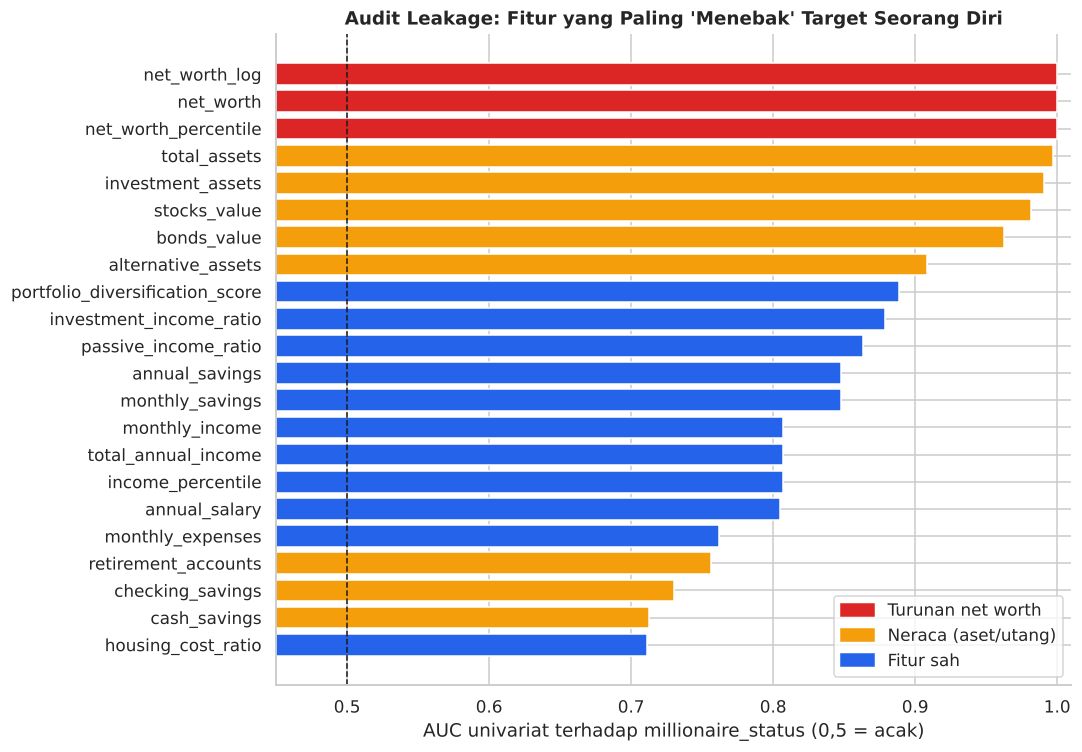

Dari 22 fitur 'paling prediktif', 11 adalah kolom turunan net worth / neraca.


In [6]:
# Kekuatan prediksi SATU fitur saja (AUC univariat): seberapa 'bocor' tiap kolom?
META = ["synthetic_person_id", "dataset_version", "generation_seed", "currency", "exchange_rate_to_usd"]
TARGET_DERIVED = ["net_worth", "net_worth_log", "net_worth_percentile", "wealth_bracket", "wealth_category",
                  "multi_millionaire_status", "financial_independence_status"]
BALANCE_SHEET = ["total_assets", "total_liabilities", "total_debt"] + BAL_ASSETS + BAL_LIAB

num_all = [c for c in df.select_dtypes("number").columns if c != TARGET]
uni_auc = {}
for c in num_all:
    x = df[c]
    if x.nunique(dropna=True) < 2: continue
    a = roc_auc_score(y_all, x.fillna(x.median()))
    uni_auc[c] = max(a, 1 - a)
uni_auc = pd.Series(uni_auc).sort_values(ascending=False)

def role(c):
    if c in TARGET_DERIVED: return "Turunan net worth"
    if c in BALANCE_SHEET:  return "Neraca (aset/utang)"
    if c in META:           return "Metadata"
    return "Fitur sah"

top = uni_auc.head(22)
colors = {"Turunan net worth": C["red"], "Neraca (aset/utang)": C["orange"], "Metadata": C["gray"], "Fitur sah": C["blue"]}
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.index[::-1], top.values[::-1], color=[colors[role(c)] for c in top.index[::-1]])
ax.axvline(0.5, color="k", ls="--", lw=1)
ax.set_xlim(0.45, 1.01); ax.set_xlabel("AUC univariat terhadap millionaire_status (0,5 = acak)")
ax.set_title("Audit Leakage: Fitur yang Paling 'Menebak' Target Seorang Diri")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in colors.items() if k != "Metadata"], loc="lower right")
savefig("03_audit_leakage"); plt.show()

n_leaky_top = sum(role(c) != "Fitur sah" for c in top.index)
print(f"Dari 22 fitur 'paling prediktif', {n_leaky_top} adalah kolom turunan net worth / neraca.")

### Tiga set fitur yang dibandingkan

| Set | Nama | Apa yang dibuang | Tujuan |
|:--|:--|:--|:--|
| **A** | *Leaky (draf lama)* | Hanya metadata, `net_worth*`, `wealth_*`, `total_assets`, `total_liabilities` | **Hanya untuk ablation** — mengukur seberapa besar komponen neraca "membantu" model secara tidak sah |
| **B** | *Bersih (utama)* | Semua dari A **+** seluruh komponen aset/utang **+** `total_debt` | **Set utama** untuk semua eksperimen & kesimpulan |
| **C** | *Tanpa arus uang* | Semua dari B **+** kolom arus uang (pendapatan, tabungan, investasi, pengeluaran, rasio turunannya) & komposisi portofolio. Tersisa: kebiasaan, psikologi, karier, **demografi** | Menjawab: *seberapa jauh perilaku, karier & demografi — tanpa nominal uang — bisa memprediksi?* |
| **D** | *C tanpa indeks komposit* | Semua dari C **+** kolom berakhiran `_index` (indeks komposit seperti `wealth_building_index` yang mungkin dibangun dari sinyal keuangan) | Batas bawah paling ketat: perilaku, karier & demografi saja |

In [7]:
STRICT_EXTRA = [
    # pendapatan & arus kas
    "annual_salary", "annual_bonus", "other_income", "total_annual_income", "income_percentile", "monthly_income",
    "monthly_expenses", "monthly_savings", "annual_savings", "side_business_income", "passive_business_income",
    "business_revenue", "business_profit", "business_profit_margin",
    # investasi (jumlah uang) & komposisi portofolio
    "monthly_investment_amount", "annual_investment_amount", "stock_allocation", "bond_allocation",
    "real_estate_allocation", "cash_allocation", "alternative_asset_allocation", "portfolio_diversification_score",
    "asset_diversification_score", "retirement_investment_rate",
    # pengeluaran & utang (nominal)
    "annual_housing_cost", "annual_transport_cost", "annual_food_cost", "annual_entertainment_cost",
    "annual_travel_cost", "annual_health_cost", "annual_education_cost", "annual_luxury_spending",
    "annual_charity_donations", "mortgage_payment", "loan_payment", "credit_card_balance", "debt_to_income_ratio",
    # rasio & status turunan dari uang
    "savings_rate", "investment_rate", "passive_income_ratio", "investment_income_ratio", "business_income_ratio",
    "housing_cost_ratio", "luxury_spending_ratio", "emergency_fund_months", "financial_buffer_months",
    "high_saver_status", "high_investor_status", "entrepreneur_status", "high_debt_risk", "financial_stability_score",
]
STRICT_EXTRA = [c for c in STRICT_EXTRA if c in df.columns]

# Set A meniru persis daftar kolom yang dibuang di draf lama (14 kolom)
DROP_A = META + TARGET_DERIVED + ["total_assets", "total_liabilities"]
DROP_B = sorted(set(META + TARGET_DERIVED + BALANCE_SHEET))
DROP_C = sorted(set(DROP_B + STRICT_EXTRA))

ALL_FEATS = [c for c in df.columns if c != TARGET]
DROP_D = sorted(set(DROP_C + [c for c in ALL_FEATS if "_index" in c]))
FEATURE_SETS = {
    "A (leaky / draf lama)": [c for c in ALL_FEATS if c not in DROP_A],
    "B (bersih / utama)":    [c for c in ALL_FEATS if c not in DROP_B],
    "C (tanpa arus uang)":   [c for c in ALL_FEATS if c not in DROP_C],
    "D (C tanpa indeks komposit)": [c for c in ALL_FEATS if c not in DROP_D],
}
summary = pd.DataFrame({"Kolom dibuang": [len(DROP_A), len(DROP_B), len(DROP_C), len(DROP_D)],
                        "Fitur tersisa": [len(v) for v in FEATURE_SETS.values()]}, index=FEATURE_SETS.keys())
display(summary)
FEATURES_MAIN = FEATURE_SETS["B (bersih / utama)"]

,Kolom dibuang,Fitur tersisa
A (leaky / draf lama),14,259
B (bersih / utama),31,242
C (tanpa arus uang),82,191
D (C tanpa indeks komposit),85,188


---
## 6. Pembagian Data & Preprocessing

- **Split**: *stratified* 80% *train* / 10% *validation* / 10% *test* (satu kali, `random_state=42`).
  - *Train* → mengoptimasi bobot · *Validation* → early stopping, tuning, pemilihan model · **Test → hanya untuk laporan akhir (Bagian 12)**.
- **Preprocessing** (di-*fit* **hanya** pada data latih; di CV di-*fit* ulang di setiap fold):
  numerik → *median imputation* + `StandardScaler`; kategorikal → imputasi `'Missing'` + `OneHotEncoder(handle_unknown='ignore')`.

In [8]:
idx_all = np.arange(len(df))
idx_tmp, idx_test = train_test_split(idx_all, test_size=0.10, random_state=SEED, stratify=y_all)
idx_train, idx_val = train_test_split(idx_tmp, test_size=1/9, random_state=SEED, stratify=y_all[idx_tmp])
Y = torch.tensor(y_all, dtype=torch.float32)

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

def clean_frame(feature_cols):
    X = df[feature_cols].copy()
    for c in X.select_dtypes("bool").columns: X[c] = X[c].astype(int)
    num = X.select_dtypes("number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    return X, num, cat

def build_matrices(feature_cols, idx_fit, idx_list):
    # Fit preprocessor pada idx_fit saja, transform ke semua idx di idx_list -> list tensor float32.
    X, num, cat = clean_frame(feature_cols)
    prep = make_preprocessor(num, cat).fit(X.iloc[idx_fit])
    mats = [torch.from_numpy(prep.transform(X.iloc[i]).astype(np.float32)) for i in idx_list]
    return prep, mats, num, cat

def feature_groups(prep, num, cat):
    # Peta: nama kolom asli -> daftar indeks kolom hasil transform (one-hot digabung per kolom asli).
    groups, pos = {}, 0
    for c in num: groups[c] = [pos]; pos += 1
    ohe = prep.named_transformers_["cat"].named_steps["ohe"]
    for c, cats in zip(cat, ohe.categories_):
        groups[c] = list(range(pos, pos + len(cats))); pos += len(cats)
    return groups

def prepare(feature_cols):
    prep, (Xtr, Xva, Xte), num, cat = build_matrices(feature_cols, idx_train, [idx_train, idx_val, idx_test])
    return SimpleNamespace(prep=prep, Xtr=Xtr, Xva=Xva, Xte=Xte, ytr=Y[idx_train], yva=Y[idx_val], yte=Y[idx_test],
                           num=num, cat=cat, groups=feature_groups(prep, num, cat), cols=feature_cols, dim=Xtr.shape[1])

t0 = time.time()
D = prepare(FEATURES_MAIN)      # data utama (Set B)
print(f"Train {len(idx_train):,} | Val {len(idx_val):,} | Test {len(idx_test):,}   (proporsi positif: "
      f"{Y[idx_train].mean():.3f} / {Y[idx_val].mean():.3f} / {Y[idx_test].mean():.3f})")
print(f"Set B: {len(FEATURES_MAIN)} kolom asli → {D.dim} fitur setelah one-hot  ({len(D.num)} numerik, {len(D.cat)} kategorikal)  [{time.time()-t0:.1f} dtk]")

Train 80,000 | Val 10,000 | Test 10,000   (proporsi positif: 0.425 / 0.425 / 0.425)
Set B: 242 kolom asli → 537 fitur setelah one-hot  (202 numerik, 40 kategorikal)  [4.7 dtk]


---
## 7. Desain Arsitektur
Tiga arsitektur dengan kapasitas dan teknik regularisasi yang berbeda, **dilatih dengan resep yang identik** agar perbandingan adil.

| Model | Struktur | Ide utama |
|:--|:--|:--|
| **Baseline MLP** | $D \to 128 \to 64 \to 1$ (ReLU) | Pembanding sederhana tanpa regularisasi |
| **Deep Regularized MLP** | $D \to 256 \to 128 \to 64 \to 32 \to 1$ + BatchNorm + Dropout | Lebih dalam; BatchNorm menstabilkan aktivasi, Dropout menekan *overfitting* |
| **Tabular ResNet** | Proyeksi $D\to w$ → 3 blok residual → head | *Skip connection* $x_{l+1}=x_l+\mathcal{F}(x_l)$ (Gorishniy dkk., 2021) |

Keluaran semua model adalah **logit** (tanpa sigmoid) dan dilatih dengan `BCEWithLogitsLoss` yang stabil secara numerik.

In [9]:
class BaselineMLP(nn.Module):
    def __init__(self, d, h1=128, h2=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h1), nn.ReLU(), nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, 1))
    def forward(self, x): return self.net(x)

class DeepRegularizedMLP(nn.Module):
    def __init__(self, d, dropout=0.25):
        super().__init__()
        def blk(i, o, p): return [nn.Linear(i, o), nn.BatchNorm1d(o), nn.ReLU()] + ([nn.Dropout(p)] if p > 0 else [])
        self.net = nn.Sequential(*blk(d, 256, dropout), *blk(256, 128, dropout*0.8), *blk(128, 64, dropout*0.5),
                                 *blk(64, 32, 0.0), nn.Linear(32, 1))
    def forward(self, x): return self.net(x)

class ResBlock(nn.Module):
    def __init__(self, w, dropout):
        super().__init__()
        self.f = nn.Sequential(nn.BatchNorm1d(w), nn.Linear(w, w), nn.GELU(), nn.Dropout(dropout),
                               nn.Linear(w, w), nn.Dropout(dropout))
    def forward(self, x): return x + self.f(x)          # skip connection

class TabularResNet(nn.Module):
    def __init__(self, d, width=128, n_blocks=3, dropout=0.2):
        super().__init__()
        self.inp = nn.Linear(d, width)
        self.blocks = nn.Sequential(*[ResBlock(width, dropout) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.BatchNorm1d(width), nn.GELU(), nn.Linear(width, 1))
    def forward(self, x): return self.head(self.blocks(self.inp(x)))

ARCHS = {"Baseline MLP": BaselineMLP, "Deep Regularized MLP": DeepRegularizedMLP, "Tabular ResNet": TabularResNet}
DEFAULT_KW = {"Baseline MLP": dict(h1=128, h2=64), "Deep Regularized MLP": dict(dropout=0.25),
              "Tabular ResNet": dict(width=128, dropout=0.2)}

def build_model(name, d, seed=SEED, **kw):
    seed_everything(seed)                                  # inisialisasi bobot reprodusibel
    return ARCHS[name](d, **{**DEFAULT_KW[name], **kw})

n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print(pd.DataFrame({n: {"Parameter": n_params(build_model(n, D.dim))} for n in ARCHS}).T.to_string())

                      Parameter
Baseline MLP              77185
Deep Regularized MLP     181953
Tabular ResNet           169089


---
## 8. Fungsi Pelatihan & Evaluasi

**Resep latih (sama untuk semua model):** optimizer AdamW ($\eta=10^{-3}$, weight decay $10^{-4}$), batch 512, `ReduceLROnPlateau` (faktor 0,5; sabar 2 epoch), *early stopping* pada `val_loss` (sabar 6 epoch) dan **bobot terbaik dikembalikan secara eksplisit** (disimpan pada epoch dengan `val_loss` terendah).

> Kurva *train* dihitung dalam mode `eval()` pada subset tetap 20.000 data latih, sehingga perbandingan *train vs validation* adil (Dropout/BatchNorm tidak mengotori kurva).

In [10]:
@torch.no_grad()
def predict_logits(model, X, bs=8192):
    model.eval()
    return torch.cat([model(X[i:i+bs]) for i in range(0, len(X), bs)]).squeeze(1)

def metrics_from_logits(y, logits, thr=0.5):
    p = torch.sigmoid(logits).numpy(); yt = y.numpy(); pred = (p >= thr).astype(int)
    return dict(loss=float(F.binary_cross_entropy_with_logits(logits, y)),
                accuracy=accuracy_score(yt, pred), precision=precision_score(yt, pred, zero_division=0),
                recall=recall_score(yt, pred, zero_division=0), f1=f1_score(yt, pred, zero_division=0),
                roc_auc=roc_auc_score(yt, p), pr_auc=average_precision_score(yt, p), brier=brier_score_loss(yt, p))

def evaluate(model, X, y, thr=0.5):
    return metrics_from_logits(y, predict_logits(model, X), thr)

def make_optimizer(name, params, lr, wd):
    if name == "adamw":   return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=wd)
    raise ValueError(name)

def fit(model, Xtr, ytr, Xva, yva, lr=LR, wd=WD, optimizer="adamw", max_epochs=MAX_EPOCHS,
        patience=PATIENCE, bs=BATCH_SIZE, seed=SEED, track_train=True):
    # Latih model; kembalikan (model dengan bobot terbaik, history, best_epoch, waktu).
    opt = make_optimizer(optimizer, model.parameters(), lr, wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
    g = torch.Generator().manual_seed(seed)
    sub = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(0))[:20000]   # subset tetap utk kurva train
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best, best_state, best_ep, wait, t0 = float("inf"), None, 0, 0, time.time()
    for ep in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g)
        for i in range(0, len(perm), bs):
            b = perm[i:i+bs]
            if len(b) < 2: continue                               # BatchNorm butuh >1 sampel
            opt.zero_grad(); loss = F.binary_cross_entropy_with_logits(model(Xtr[b]).squeeze(1), ytr[b]); loss.backward(); opt.step()
        lv = predict_logits(model, Xva); vl = float(F.binary_cross_entropy_with_logits(lv, yva))
        hist["val_loss"].append(vl); hist["val_acc"].append(float(((lv > 0).float() == yva).float().mean()))
        if track_train:
            lt = predict_logits(model, Xtr[sub])
            hist["train_loss"].append(float(F.binary_cross_entropy_with_logits(lt, ytr[sub])))
            hist["train_acc"].append(float(((lt > 0).float() == ytr[sub]).float().mean()))
        sched.step(vl)
        if vl < best - 1e-5:
            best, best_ep, wait = vl, ep, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)                              # kembalikan bobot terbaik
    return model, hist, best_ep, time.time() - t0

# Uji cepat fungsi (smoke test) pada 1 epoch
_m = build_model("Baseline MLP", D.dim)
_m, _h, _b, _t = fit(_m, D.Xtr, D.ytr, D.Xva, D.yva, max_epochs=1)
print(f"Smoke test OK — 1 epoch Baseline MLP: val_loss={_h['val_loss'][0]:.4f}, val_acc={_h['val_acc'][0]:.4f}  ({_t:.1f} dtk)")

Smoke test OK — 1 epoch Baseline MLP: val_loss=0.1533, val_acc=0.9346  (0.4 dtk)


---
## 9. Eksperimen 1 — Benchmark 3 Arsitektur dengan 5-Fold Cross-Validation

Ketiga arsitektur dilatih pada **5 fold stratified** dari data *train+validation* (90.000 data) dengan resep yang identik; preprocessing di-*fit* ulang di setiap fold (tanpa kebocoran statistik). *Test set tidak disentuh.*

**Aturan pemilihan champion (1-Standard-Error):** ambil model dengan `val_loss` rata-rata terendah; jika ada model lain yang selisihnya masih dalam 1 SE, pilih yang **paling sederhana** (parameter paling sedikit). Prinsip: jangan memakai model rumit bila tidak terbukti lebih baik.

In [11]:
idx_tv = np.concatenate([idx_train, idx_val])
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
cv_rows = []
t_start = time.time()
for fold, (a, b) in enumerate(skf.split(idx_tv, y_all[idx_tv]), 1):
    prep_f, (Xa, Xb), _, _ = build_matrices(FEATURES_MAIN, idx_tv[a], [idx_tv[a], idx_tv[b]])
    ya, yb = Y[idx_tv[a]], Y[idx_tv[b]]
    for name in ARCHS:
        m = build_model(name, Xa.shape[1], seed=SEED + fold)
        m, h, be, dt = fit(m, Xa, ya, Xb, yb, seed=SEED + fold, track_train=False)
        r = evaluate(m, Xb, yb); r.update(model=name, fold=fold, best_epoch=be, seconds=dt, params=n_params(m))
        cv_rows.append(r)
    print(f"  fold {fold}/{CV_FOLDS} selesai  ({time.time()-t_start:.0f} dtk)")
cv = pd.DataFrame(cv_rows)
cv.to_csv(OUT_DIR / "cv_results_per_fold.csv", index=False)

agg = cv.groupby("model").agg(
    val_loss=("loss", "mean"), val_loss_sd=("loss", "std"), accuracy=("accuracy", "mean"), accuracy_sd=("accuracy", "std"),
    f1=("f1", "mean"), roc_auc=("roc_auc", "mean"), roc_auc_sd=("roc_auc", "std"),
    best_epoch=("best_epoch", "mean"), seconds=("seconds", "mean"), params=("params", "first")).loc[list(ARCHS)]
display(agg.style.format({"val_loss": "{:.4f}", "val_loss_sd": "{:.4f}", "accuracy": "{:.4f}", "accuracy_sd": "{:.4f}",
                          "f1": "{:.4f}", "roc_auc": "{:.4f}", "roc_auc_sd": "{:.4f}", "best_epoch": "{:.1f}",
                          "seconds": "{:.1f}", "params": "{:,.0f}"}).background_gradient(subset=["val_loss"], cmap="RdYlGn_r"))

# ---- Aturan champion (1-SE) ----
best_name = agg["val_loss"].idxmin()
se_best = agg.loc[best_name, "val_loss_sd"] / np.sqrt(CV_FOLDS)
within = agg[agg["val_loss"] <= agg.loc[best_name, "val_loss"] + se_best]
CHAMPION = within["params"].idxmin()
print(f"\nVal loss terendah : {best_name}   (SE = {se_best:.4f})")
print(f"Kandidat dalam 1 SE: {list(within.index)}")
print(f"🏆 CHAMPION        : {CHAMPION}")

  fold 1/5 selesai  (43 dtk)


  fold 2/5 selesai  (91 dtk)


  fold 3/5 selesai  (134 dtk)


  fold 4/5 selesai  (178 dtk)


  fold 5/5 selesai  (220 dtk)


,val_loss,val_loss_sd,accuracy,accuracy_sd,f1,roc_auc,roc_auc_sd,best_epoch,seconds,params
model,,,,,,,,,,
Baseline MLP,0.0891,0.0028,0.9626,0.0021,0.9559,0.9954,0.0005,5.8,3.8,"77,185"
Deep Regularized MLP,0.0929,0.0033,0.9611,0.0021,0.9541,0.9949,0.0003,5.2,12.8,"181,953"
Tabular ResNet,0.0844,0.0030,0.9639,0.0018,0.9575,0.9957,0.0003,9.2,23.4,"169,089"



Val loss terendah : Tabular ResNet   (SE = 0.0013)
Kandidat dalam 1 SE: ['Tabular ResNet']
🏆 CHAMPION        : Tabular ResNet


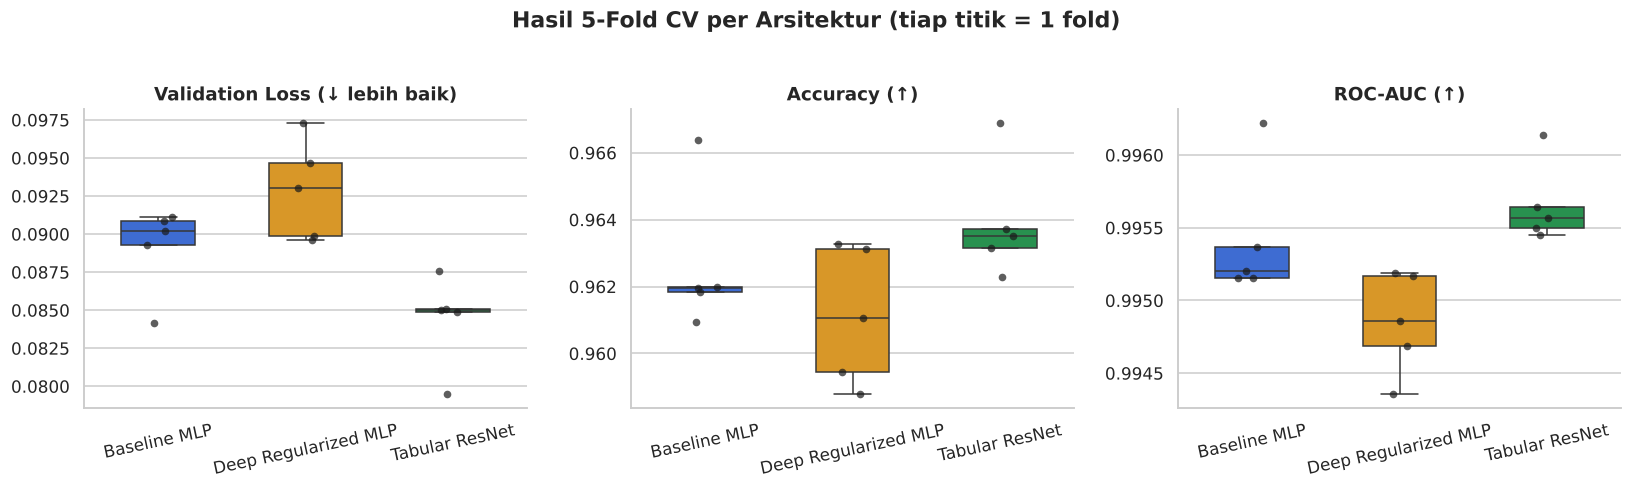

,Δ val_loss vs Baseline (rata-rata),Fold di mana lebih baik dari Baseline
Deep Regularized MLP,0.003766,0/5
Tabular ResNet,-0.004719,5/5


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (col, title) in zip(axes, [("loss", "Validation Loss (↓ lebih baik)"), ("accuracy", "Accuracy (↑)"), ("roc_auc", "ROC-AUC (↑)")]):
    sns.boxplot(data=cv, x="model", y=col, order=list(ARCHS), palette=MODEL_COLORS, ax=ax, width=.5, fliersize=0)
    sns.stripplot(data=cv, x="model", y=col, order=list(ARCHS), color="k", size=5, ax=ax, alpha=.7)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", rotation=12)
fig.suptitle(f"Hasil {CV_FOLDS}-Fold CV per Arsitektur (tiap titik = 1 fold)", fontweight="bold", y=1.03)
savefig("04_cv_benchmark"); plt.show()

# Perbandingan berpasangan terhadap Baseline (fold yang sama)
piv = cv.pivot(index="fold", columns="model", values="loss")
pair = pd.DataFrame({m: {"Δ val_loss vs Baseline (rata-rata)": (piv[m]-piv["Baseline MLP"]).mean(),
                         "Fold di mana lebih baik dari Baseline": f"{int((piv[m] < piv['Baseline MLP']).sum())}/{CV_FOLDS}"}
                     for m in ARCHS if m != "Baseline MLP"}).T
display(pair)

**Cara membaca:** boxplot memperlihatkan variasi antar fold. Bila kotak dua model saling tumpang tindih, selisih rata-ratanya **belum tentu bermakna**. Tabel berpasangan menunjukkan di berapa fold sebuah model benar-benar mengalahkan *Baseline* (Δ negatif = lebih baik).

---
## 10. Eksperimen 2 — Hyperparameter Tuning pada Champion

Tuning dilakukan **hanya pada champion** dan dinilai dengan *validation set* (data *test* tidak disentuh). Grid 3×3×3 = 27 kombinasi:

| Hyperparameter | Nilai |
|:--|:--|
| Learning rate | 1e-4, 3e-4, 1e-3 |
| Weight decay (AdamW) | 1e-4, 1e-2, 1e-1 *(pada AdamW peluruhan bobot dikalikan learning rate, sehingga nilai kecil seperti 1e-5 praktis tak berefek)* |
| Kapasitas / regularisasi | Baseline: lebar (32-16, 64-32, 128-64) · Deep MLP: dropout (0,1/0,25/0,4) · ResNet: lebar (32/64/128) |

In [13]:
CAP_GRID = {
    "Baseline MLP":         [dict(h1=32, h2=16), dict(h1=64, h2=32), dict(h1=128, h2=64)],
    "Deep Regularized MLP": [dict(dropout=0.10), dict(dropout=0.25), dict(dropout=0.40)],
    "Tabular ResNet":       [dict(width=32, dropout=0.2), dict(width=64, dropout=0.2), dict(width=128, dropout=0.2)],
}
cap_label = lambda kw: ", ".join(f"{k}={v}" for k, v in kw.items())

grid_rows, t0 = [], time.time()
for lr in [1e-4, 3e-4, 1e-3]:
    for wd in [1e-4, 1e-2, 1e-1]:
        for kw in CAP_GRID[CHAMPION]:
            m = build_model(CHAMPION, D.dim, **kw)
            m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=lr, wd=wd, track_train=False)
            r = evaluate(m, D.Xva, D.yva)
            grid_rows.append(dict(lr=lr, wd=wd, capacity=cap_label(kw), kw=kw, val_loss=r["loss"], val_acc=r["accuracy"],
                                  val_auc=r["roc_auc"], best_epoch=be))
grid = pd.DataFrame(grid_rows)
print(f"Grid selesai: {len(grid)} kombinasi dalam {time.time()-t0:.0f} dtk")

best_row = grid.loc[grid["val_loss"].idxmin()]
BEST_KW, BEST_LR, BEST_WD = best_row["kw"], float(best_row["lr"]), float(best_row["wd"])
display(grid.drop(columns="kw").sort_values("val_loss").head(8).style.format(
    {"lr": "{:.0e}", "wd": "{:.0e}", "val_loss": "{:.4f}", "val_acc": "{:.4f}", "val_auc": "{:.4f}"}))
print(f"✅ Konfigurasi terbaik (val_loss) → lr={BEST_LR:g}, wd={BEST_WD:g}, {cap_label(BEST_KW)}")
_cap_list = [cap_label(k) for k in CAP_GRID[CHAMPION]]
_edges = []
if BEST_LR in (1e-4, 1e-3): _edges.append("learning rate")
if BEST_WD in (1e-4, 1e-1): _edges.append("weight decay")
if cap_label(BEST_KW) in (_cap_list[0], _cap_list[-1]): _edges.append("kapasitas")
print("ℹ️ Optimum berada di TEPI grid untuk: " + ", ".join(_edges) + " → ruang pencarian bisa diperluas bila ada waktu." if _edges else "ℹ️ Optimum berada di bagian dalam grid (bukan di tepi) → rentang pencarian memadai.")

Grid selesai: 27 kombinasi dalam 793 dtk


,lr,wd,capacity,val_loss,val_acc,val_auc,best_epoch
15,3e-04,1e-01,"width=32, dropout=0.2",0.0700,0.9697,0.9970,30
12,3e-04,1e-02,"width=32, dropout=0.2",0.0701,0.9689,0.9970,30
9,3e-04,1e-04,"width=32, dropout=0.2",0.0709,0.9695,0.9969,30
16,3e-04,1e-01,"width=64, dropout=0.2",0.0709,0.9693,0.9969,25
13,3e-04,1e-02,"width=64, dropout=0.2",0.0713,0.9692,0.9969,25
10,3e-04,1e-04,"width=64, dropout=0.2",0.0714,0.9691,0.9969,25
21,1e-03,1e-02,"width=32, dropout=0.2",0.0731,0.9673,0.9968,15
18,1e-03,1e-04,"width=32, dropout=0.2",0.0731,0.9672,0.9968,15


✅ Konfigurasi terbaik (val_loss) → lr=0.0003, wd=0.1, width=32, dropout=0.2
ℹ️ Optimum berada di TEPI grid untuk: weight decay, kapasitas → ruang pencarian bisa diperluas bila ada waktu.


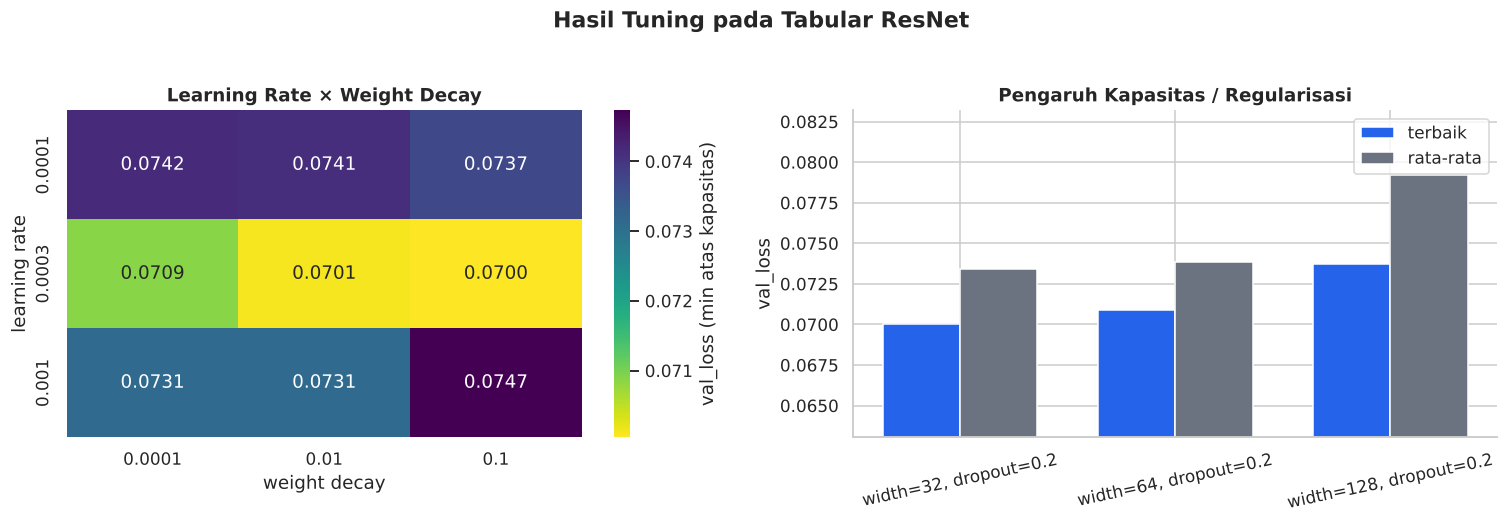

Rentang val_loss di seluruh grid: 0.0700 – 0.0848 (selisih 0.0148)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
piv_lw = grid.pivot_table(index="lr", columns="wd", values="val_loss", aggfunc="min")
sns.heatmap(piv_lw, annot=True, fmt=".4f", cmap="viridis_r", ax=axes[0], cbar_kws={"label": "val_loss (min atas kapasitas)"})
axes[0].set_title("Learning Rate × Weight Decay"); axes[0].set_ylabel("learning rate"); axes[0].set_xlabel("weight decay")

cap_df = grid.groupby("capacity")["val_loss"].agg(["min", "mean"]).reindex([cap_label(k) for k in CAP_GRID[CHAMPION]])
x = np.arange(len(cap_df))
axes[1].bar(x-.18, cap_df["min"], .36, label="terbaik", color=C["blue"]); axes[1].bar(x+.18, cap_df["mean"], .36, label="rata-rata", color=C["gray"])
axes[1].set_xticks(x); axes[1].set_xticklabels(cap_df.index, rotation=12); axes[1].legend()
axes[1].set_title("Pengaruh Kapasitas / Regularisasi"); axes[1].set_ylabel("val_loss")
axes[1].set_ylim(cap_df["min"].min()*0.9, cap_df["mean"].max()*1.05)
fig.suptitle(f"Hasil Tuning pada {CHAMPION}", fontweight="bold", y=1.03)
savefig("05_tuning"); plt.show()
spread = grid["val_loss"].max() - grid["val_loss"].min()
print(f"Rentang val_loss di seluruh grid: {grid['val_loss'].min():.4f} – {grid['val_loss'].max():.4f} (selisih {spread:.4f})")

In [15]:
# Perbandingan optimizer pada konfigurasi terbaik (validation set)
opt_rows = []
for opt_name, lr_o in [("adamw", BEST_LR), ("sgd", 1e-2), ("rmsprop", 1e-3)]:
    m = build_model(CHAMPION, D.dim, **BEST_KW)
    m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=lr_o, wd=BEST_WD, optimizer=opt_name, track_train=False)
    r = evaluate(m, D.Xva, D.yva)
    opt_rows.append(dict(optimizer=opt_name, lr=lr_o, val_loss=r["loss"], val_acc=r["accuracy"], val_auc=r["roc_auc"], best_epoch=be, detik=dt))
opt_df = pd.DataFrame(opt_rows).set_index("optimizer")
display(opt_df.style.format({"lr": "{:.0e}", "val_loss": "{:.4f}", "val_acc": "{:.4f}", "val_auc": "{:.4f}", "detik": "{:.1f}"}))
BEST_OPT = opt_df["val_loss"].idxmin()
BEST_OPT_LR = float(opt_df.loc[BEST_OPT, "lr"])
print(f"✅ Optimizer terbaik di validation: {BEST_OPT} (lr={BEST_OPT_LR:g})")

,lr,val_loss,val_acc,val_auc,best_epoch,detik
optimizer,,,,,,
adamw,3e-04,0.0700,0.9697,0.9970,30,22.3
sgd,1e-02,0.3294,0.9189,0.9821,30,17.9
rmsprop,1e-03,0.2763,0.8932,0.9610,1,4.9


✅ Optimizer terbaik di validation: adamw (lr=0.0003)


---
## 11. Eksperimen 3 — Ablation: Seberapa Besar Leakage & Peran Arus Uang?

Champion dilatih ulang pada keempat set fitur (A, B, C, D; lihat Bagian 5) dengan konfigurasi yang sama. Ini menjawab tiga pertanyaan:
1. **Berapa "keuntungan palsu"** yang didapat bila komponen neraca dibiarkan (A vs B)?
2. **Seberapa jauh perilaku, karier & demografi** — tanpa data nominal uang — masih bisa memprediksi (B vs C)?
3. **Apakah indeks komposit** (mis. `wealth_building_index`) menyumbang sinyal "terselubung" (C vs D)?

,fitur_asli,fitur_setelah_ohe,val_loss,test_acc,test_f1,test_auc,test_loss
set,,,,,,,
A (leaky / draf lama),259,554,0.0354,0.9869,0.9845,0.9994,0.0348
B (bersih / utama),242,537,0.0700,0.9715,0.9665,0.9972,0.0675
C (tanpa arus uang),191,486,0.4831,0.7688,0.7231,0.8442,0.4803
D (C tanpa indeks komposit),188,483,0.5131,0.7445,0.6946,0.8181,0.5131


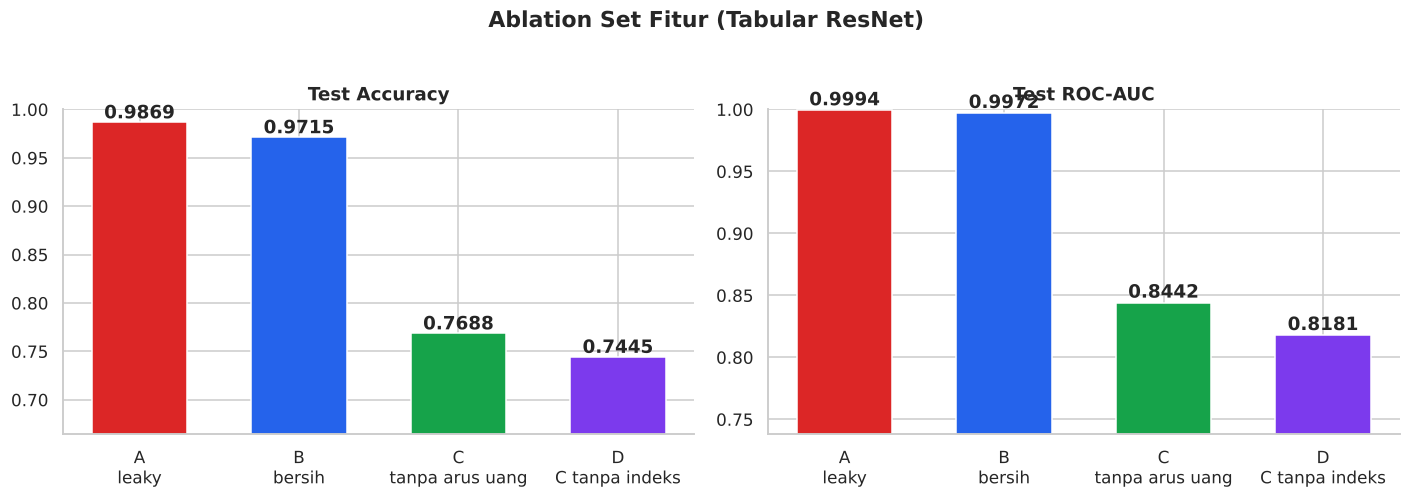

In [16]:
ablation, abl_models, abl_data = [], {}, {}
for label, cols in FEATURE_SETS.items():
    d = D if cols is FEATURES_MAIN else prepare(cols)
    m = build_model(CHAMPION, d.dim, **BEST_KW)
    m, h, be, dt = fit(m, d.Xtr, d.ytr, d.Xva, d.yva, lr=BEST_OPT_LR, wd=BEST_WD, optimizer=BEST_OPT, track_train=False)
    rv, rt = evaluate(m, d.Xva, d.yva), evaluate(m, d.Xte, d.yte)
    ablation.append(dict(set=label, fitur_asli=len(cols), fitur_setelah_ohe=d.dim, val_loss=rv["loss"],
                         test_acc=rt["accuracy"], test_f1=rt["f1"], test_auc=rt["roc_auc"], test_loss=rt["loss"]))
    abl_models[label], abl_data[label] = m, d
abl = pd.DataFrame(ablation).set_index("set")
display(abl.style.format({"val_loss": "{:.4f}", "test_acc": "{:.4f}", "test_f1": "{:.4f}", "test_auc": "{:.4f}", "test_loss": "{:.4f}"})
        .background_gradient(subset=["test_acc"], cmap="Blues"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
cols_ab = [C["red"], C["blue"], C["green"], C["purple"]]
for ax, (col, title) in zip(axes, [("test_acc", "Test Accuracy"), ("test_auc", "Test ROC-AUC")]):
    ax.bar(["A\nleaky", "B\nbersih", "C\ntanpa arus uang", "D\nC tanpa indeks"], abl[col].values, color=cols_ab, width=.6)
    lo = abl[col].min(); ax.set_ylim(max(0.5, lo - 0.08), 1.0)
    for i, v in enumerate(abl[col].values): ax.text(i, v + 0.004, f"{v:.4f}", ha="center", fontweight="bold")
    ax.set_title(title)
fig.suptitle(f"Ablation Set Fitur ({CHAMPION})", fontweight="bold", y=1.03)
savefig("06_ablation_fitur"); plt.show()

---
## 12. Evaluasi Akhir pada *Test Set* (dipakai sekali)

Seluruh model dilatih pada **Set B** dengan split *train/validation* yang sama, lalu dievaluasi **satu kali** pada 10.000 data uji:
- tiga arsitektur dengan **resep default identik** (sebagai perbandingan adil & untuk kurva belajar),
- **champion yang sudah dituning**,
- dua baseline klasik: **Logistic Regression** dan **Gradient Boosting** (`HistGradientBoostingClassifier`).

In [17]:
final_models, final_hist, final_rows = {}, {}, []
for name in ARCHS:
    m = build_model(name, D.dim)
    m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva)
    final_models[name], final_hist[name] = m, dict(h, best_epoch=be)
    final_rows.append(dict(model=name, params=n_params(m), best_epoch=be, seconds=dt, **{f"test_{k}": v for k, v in evaluate(m, D.Xte, D.yte).items()}))

# Champion hasil tuning
CH_NAME = f"{CHAMPION} (tuned)"
m = build_model(CHAMPION, D.dim, **BEST_KW)
m, h, be, dt = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=BEST_OPT_LR, wd=BEST_WD, optimizer=BEST_OPT)
final_models[CH_NAME], final_hist[CH_NAME] = m, dict(h, best_epoch=be)
final_rows.append(dict(model=CH_NAME, params=n_params(m), best_epoch=be, seconds=dt, **{f"test_{k}": v for k, v in evaluate(m, D.Xte, D.yte).items()}))
CHAMP_MODEL = m

# Baseline klasik (scikit-learn)
Xtr_np, Xva_np, Xte_np = D.Xtr.numpy(), D.Xva.numpy(), D.Xte.numpy()
ytr_np, yte_np = D.ytr.numpy(), D.yte.numpy()
classic_proba = {}
for cname, clf in [("Logistic Regression", LogisticRegression(max_iter=2000, C=1.0)),
                   ("Gradient Boosting (HistGB)", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=SEED))]:
    t0 = time.time(); clf.fit(Xtr_np, ytr_np); dt = time.time() - t0
    p = np.clip(clf.predict_proba(Xte_np)[:, 1], 1e-7, 1 - 1e-7); classic_proba[cname] = p
    logits = torch.tensor(np.log(p / (1 - p)), dtype=torch.float32)
    final_rows.append(dict(model=cname, params=np.nan, best_epoch=np.nan, seconds=dt, **{f"test_{k}": v for k, v in metrics_from_logits(D.yte, logits).items()}))

final = pd.DataFrame(final_rows).set_index("model")
show_cols = ["params", "seconds", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "test_pr_auc", "test_loss"]
display(final[show_cols].style.format({"params": "{:,.0f}", "seconds": "{:.1f}", **{c: "{:.4f}" for c in show_cols[2:]}})
        .background_gradient(subset=["test_accuracy", "test_roc_auc"], cmap="Greens"))
final.to_csv(OUT_DIR / "final_test_results.csv")

,params,seconds,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc,test_loss
model,,,,,,,,,
Baseline MLP,"77,185",5.2,0.9666,0.9603,0.9612,0.9607,0.9961,0.9950,0.0875
Deep Regularized MLP,"181,953",17.9,0.9629,0.9670,0.9449,0.9558,0.9956,0.9944,0.0920
Tabular ResNet,"169,089",26.6,0.9644,0.9566,0.9598,0.9582,0.9960,0.9948,0.0804
Tabular ResNet (tuned),"23,841",23.5,0.9715,0.9666,0.9663,0.9665,0.9972,0.9964,0.0675
Logistic Regression,nan,3.2,0.9518,0.9445,0.9419,0.9432,0.9906,0.9879,0.1239
Gradient Boosting (HistGB),nan,16.2,0.9721,0.9695,0.9647,0.9671,0.9974,0.9966,0.0663


### 12.1 Kurva Belajar & Diagnosa Overfitting
Garis putus-putus vertikal menandai **epoch terbaik** (bobot yang dikembalikan). Bila *val loss* naik sementara *train loss* terus turun, itu tanda *overfitting* — dan karena bobot terbaik di-restore, model akhir tidak terdampak.

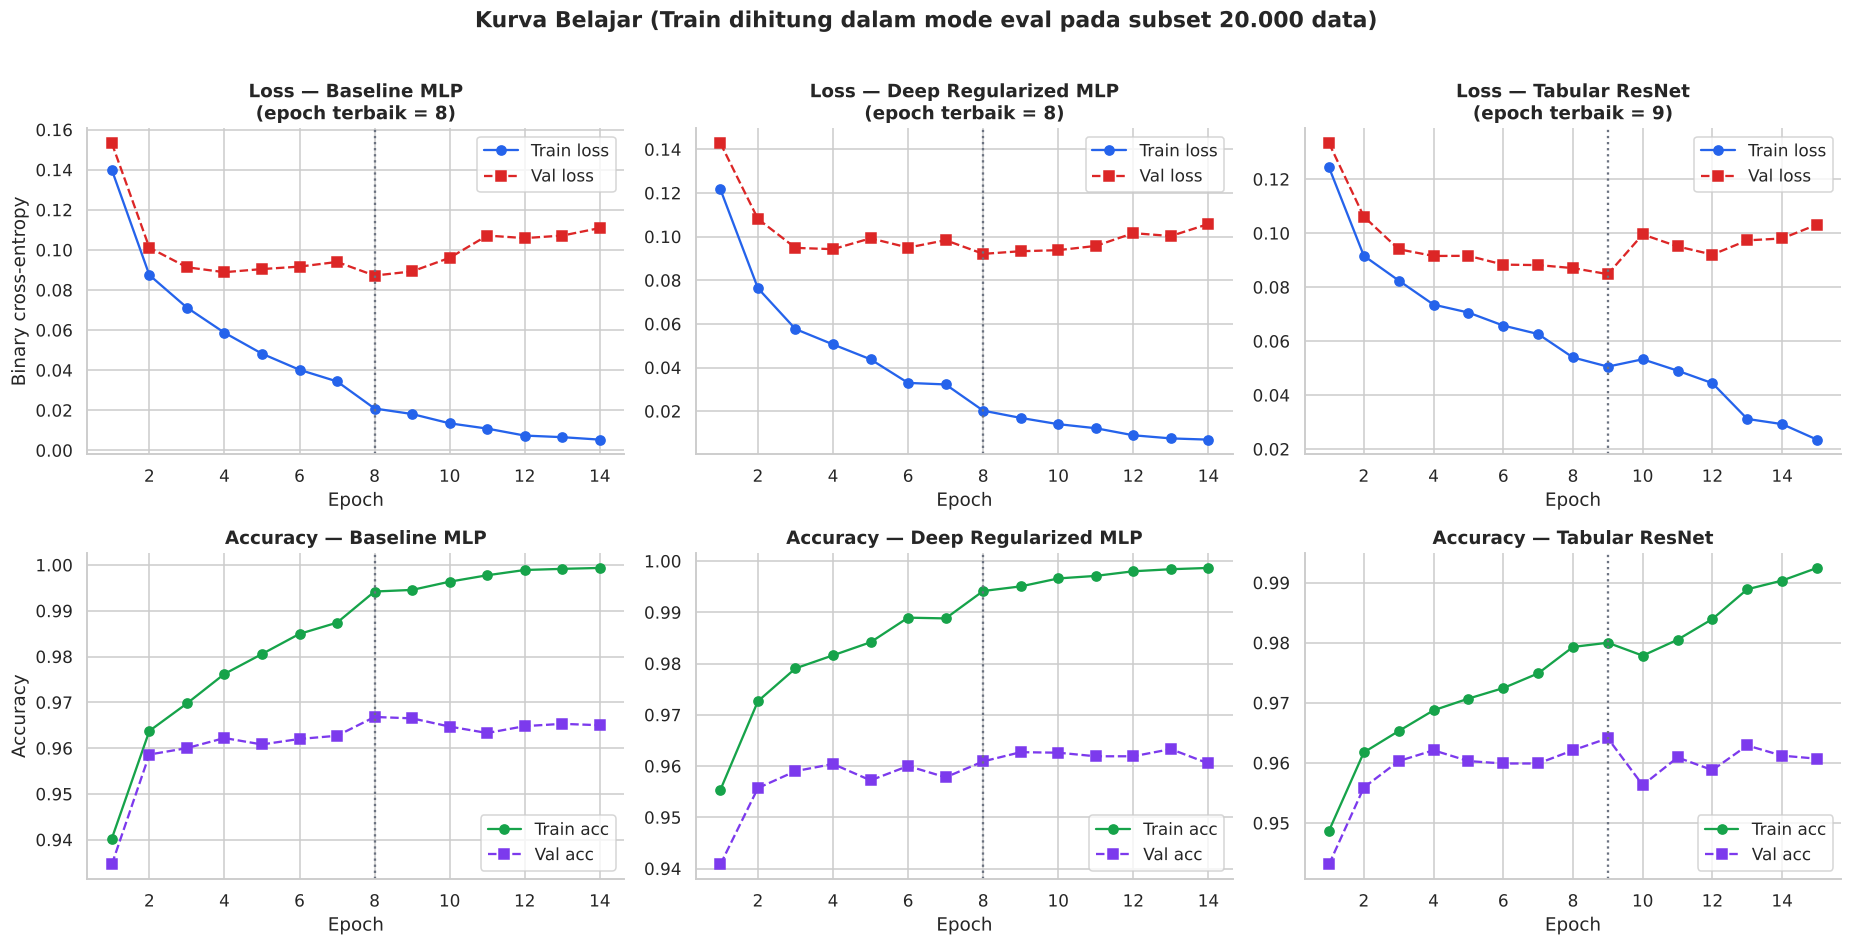

,Train loss @ terbaik,Val loss @ terbaik,Train acc @ terbaik,Val acc @ terbaik,Epoch dijalankan,Gap acc (train−val)
Baseline MLP,0.0209,0.0872,0.9942,0.9668,14,0.0274
Deep Regularized MLP,0.0202,0.0921,0.9941,0.9609,14,0.0332
Tabular ResNet,0.0506,0.0848,0.9800,0.9641,15,0.0159


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for j, name in enumerate(ARCHS):
    h = final_hist[name]; ep = np.arange(1, len(h["val_loss"]) + 1); be = h["best_epoch"]
    ax = axes[0, j]
    ax.plot(ep, h["train_loss"], "o-", color=C["blue"], label="Train loss"); ax.plot(ep, h["val_loss"], "s--", color=C["red"], label="Val loss")
    ax.axvline(be, color=C["gray"], ls=":", lw=1.5); ax.set_title(f"Loss — {name}\n(epoch terbaik = {be})"); ax.set_xlabel("Epoch"); ax.legend()
    if j == 0: ax.set_ylabel("Binary cross-entropy")
    ax = axes[1, j]
    ax.plot(ep, h["train_acc"], "o-", color=C["green"], label="Train acc"); ax.plot(ep, h["val_acc"], "s--", color=C["purple"], label="Val acc")
    ax.axvline(be, color=C["gray"], ls=":", lw=1.5); ax.set_title(f"Accuracy — {name}"); ax.set_xlabel("Epoch"); ax.legend(loc="lower right")
    if j == 0: ax.set_ylabel("Accuracy")
fig.suptitle("Kurva Belajar (Train dihitung dalam mode eval pada subset 20.000 data)", fontweight="bold", y=1.01)
savefig("07_kurva_belajar"); plt.show()

gap = pd.DataFrame({n: {"Train loss @ terbaik": final_hist[n]["train_loss"][final_hist[n]["best_epoch"]-1],
                        "Val loss @ terbaik":   final_hist[n]["val_loss"][final_hist[n]["best_epoch"]-1],
                        "Train acc @ terbaik":  final_hist[n]["train_acc"][final_hist[n]["best_epoch"]-1],
                        "Val acc @ terbaik":    final_hist[n]["val_acc"][final_hist[n]["best_epoch"]-1],
                        "Epoch dijalankan": len(final_hist[n]["val_loss"])} for n in ARCHS}).T
gap["Gap acc (train−val)"] = gap["Train acc @ terbaik"] - gap["Val acc @ terbaik"]
display(gap.style.format({c: "{:.4f}" for c in gap.columns if c != "Epoch dijalankan"} | {"Epoch dijalankan": "{:.0f}"}))

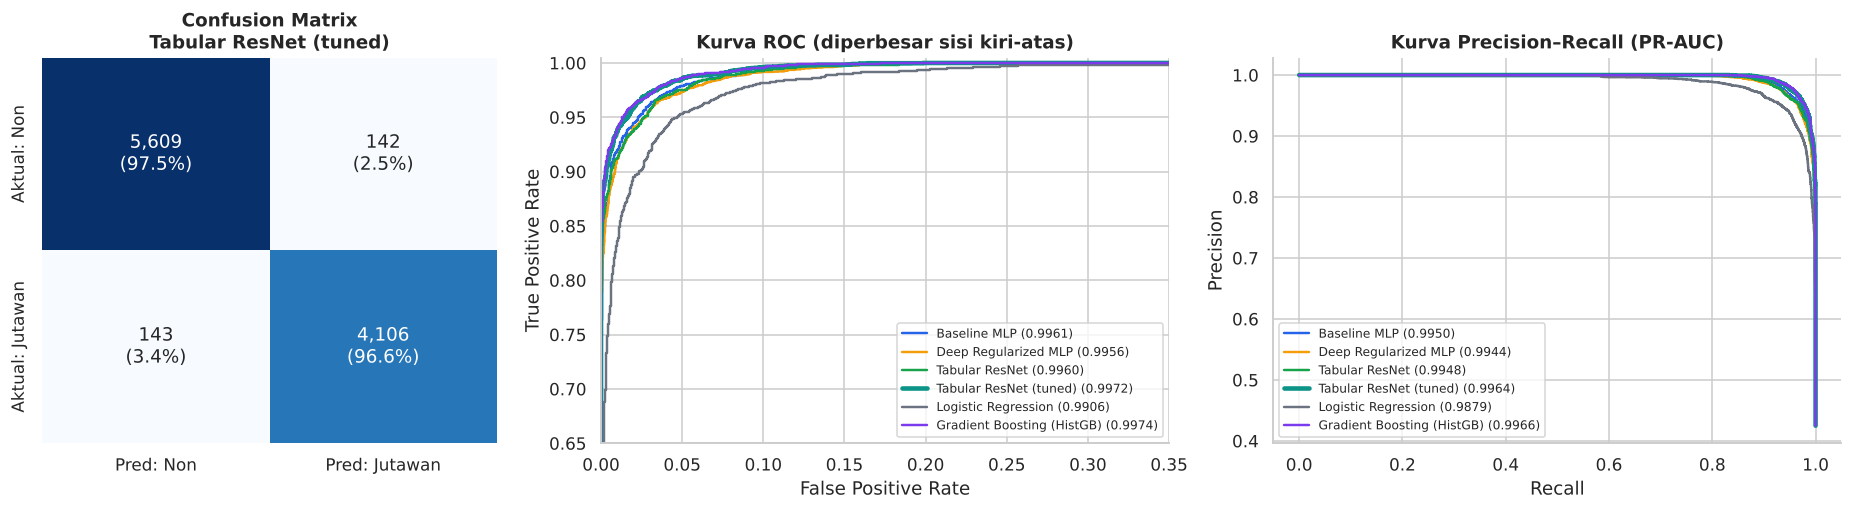

                 precision    recall  f1-score   support

Non-Millionaire     0.9751    0.9753    0.9752      5751
    Millionaire     0.9666    0.9663    0.9665      4249

       accuracy                         0.9715     10000
      macro avg     0.9709    0.9708    0.9708     10000
   weighted avg     0.9715    0.9715    0.9715     10000



In [19]:
# 12.2 Confusion matrix, ROC & PR (champion vs pembanding)
proba = {n: torch.sigmoid(predict_logits(final_models[n], D.Xte)).numpy() for n in final_models}
proba.update(classic_proba)

cm = confusion_matrix(yte_np, (proba[CH_NAME] >= 0.5).astype(int))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.25, 1.25]})
annot = np.array([[f"{v:,}\n({v/cm[i].sum()*100:.1f}%)" for v in row] for i, row in enumerate(cm)])
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Pred: Non", "Pred: Jutawan"], yticklabels=["Aktual: Non", "Aktual: Jutawan"])
axes[0].set_title(f"Confusion Matrix\n{CH_NAME}")

palette = {**MODEL_COLORS, CH_NAME: C["teal"], "Logistic Regression": C["gray"], "Gradient Boosting (HistGB)": C["purple"]}
for n, p in proba.items():
    fpr, tpr, _ = roc_curve(yte_np, p); prc, rec, _ = precision_recall_curve(yte_np, p)
    lw = 3 if n == CH_NAME else 1.6
    axes[1].plot(fpr, tpr, color=palette[n], lw=lw, label=f"{n} ({roc_auc_score(yte_np, p):.4f})")
    axes[2].plot(rec, prc, color=palette[n], lw=lw, label=f"{n} ({average_precision_score(yte_np, p):.4f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("Kurva ROC (AUC)"); axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right", fontsize=8)
axes[2].set_title("Kurva Precision–Recall (PR-AUC)"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend(loc="lower left", fontsize=8)
axes[1].set_xlim(0, .35); axes[1].set_ylim(.65, 1.005); axes[1].set_title("Kurva ROC (diperbesar sisi kiri-atas)")
savefig("08_cm_roc_pr"); plt.show()
print(classification_report(yte_np, (proba[CH_NAME] >= 0.5).astype(int), target_names=["Non-Millionaire", "Millionaire"], digits=4))

### 12.3 Kalibrasi Probabilitas & Pemilihan Threshold
*Accuracy* tinggi tidak otomatis berarti probabilitasnya **terkalibrasi**. Kurva kalibrasi memeriksa apakah "prediksi 80%" benar-benar berarti ±80% kasus positif. *Threshold* alternatif dipilih dari **validation set** (memaksimalkan F1), lalu diuji di *test*.

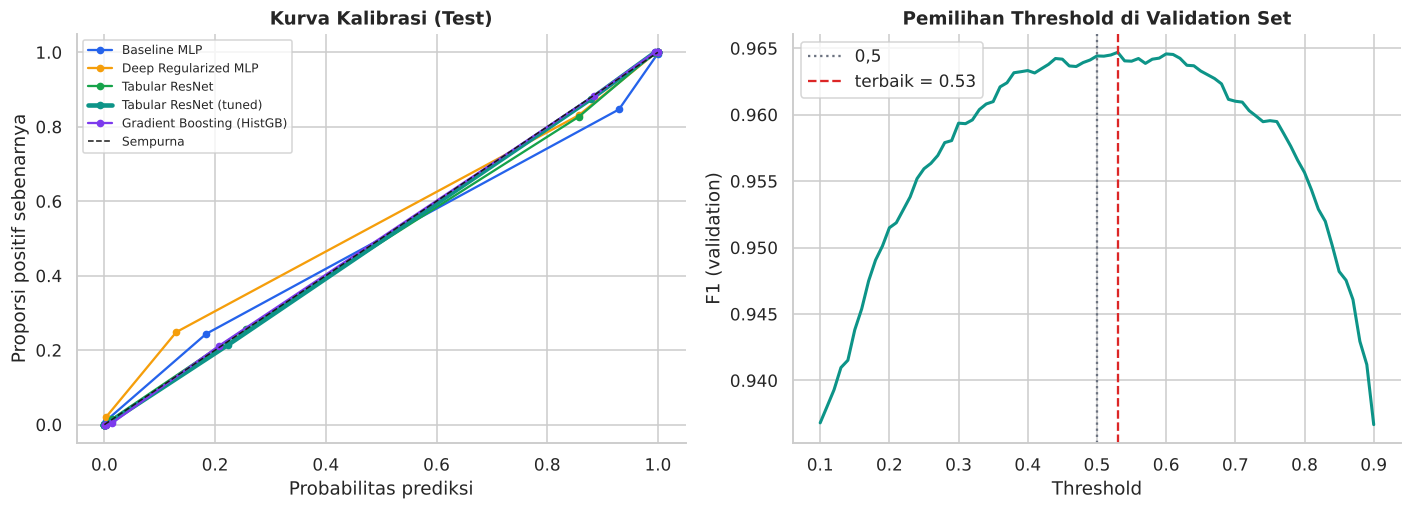

,"threshold 0,5",threshold 0.53 (dari validation)
accuracy,0.9715,0.9717
precision,0.9666,0.9686
recall,0.9663,0.9647
f1,0.9665,0.9666
brier,0.0205,0.0205


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for n in [ "Baseline MLP", "Deep Regularized MLP", "Tabular ResNet", CH_NAME, "Gradient Boosting (HistGB)"]:
    fo, mp = calibration_curve(yte_np, proba[n], n_bins=12, strategy="quantile")
    axes[0].plot(mp, fo, "o-", color=palette[n], lw=3 if n == CH_NAME else 1.5, label=n, ms=4)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Sempurna"); axes[0].set_xlabel("Probabilitas prediksi"); axes[0].set_ylabel("Proporsi positif sebenarnya")
axes[0].set_title("Kurva Kalibrasi (Test)"); axes[0].legend(fontsize=8)

pv = torch.sigmoid(predict_logits(CHAMP_MODEL, D.Xva)).numpy()
ths = np.linspace(0.1, 0.9, 81)
f1v = [f1_score(D.yva.numpy(), (pv >= t).astype(int)) for t in ths]
THR = float(ths[int(np.argmax(f1v))])
axes[1].plot(ths, f1v, color=C["teal"], lw=2); axes[1].axvline(0.5, color=C["gray"], ls=":", label="0,5"); axes[1].axvline(THR, color=C["red"], ls="--", label=f"terbaik = {THR:.2f}")
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel("F1 (validation)"); axes[1].set_title("Pemilihan Threshold di Validation Set"); axes[1].legend()
savefig("09_kalibrasi_threshold"); plt.show()

r05 = metrics_from_logits(D.yte, predict_logits(CHAMP_MODEL, D.Xte), 0.5)
rth = metrics_from_logits(D.yte, predict_logits(CHAMP_MODEL, D.Xte), THR)
display(pd.DataFrame({"threshold 0,5": r05, f"threshold {THR:.2f} (dari validation)": rth}).loc[["accuracy", "precision", "recall", "f1", "brier"]].style.format("{:.4f}"))

### 12.4 Stabilitas terhadap *Random Seed*
Hasil satu seed bisa kebetulan. Champion dilatih ulang dengan **5 seed berbeda** (split data tetap) untuk melihat sebaran performanya.

In [21]:
seed_rows = []
for s in range(N_SEEDS):
    m = build_model(CHAMPION, D.dim, seed=SEED + 100 + s, **BEST_KW)
    m, _, be, _ = fit(m, D.Xtr, D.ytr, D.Xva, D.yva, lr=BEST_OPT_LR, wd=BEST_WD, optimizer=BEST_OPT, seed=SEED + 100 + s, track_train=False)
    r = evaluate(m, D.Xte, D.yte); seed_rows.append(dict(seed=SEED + 100 + s, test_acc=r["accuracy"], test_f1=r["f1"], test_auc=r["roc_auc"], best_epoch=be))
seeds_df = pd.DataFrame(seed_rows).set_index("seed")
display(seeds_df.style.format({"test_acc": "{:.4f}", "test_f1": "{:.4f}", "test_auc": "{:.4f}"}))
SEED_STATS = seeds_df.agg(["mean", "std"])
print(f"Accuracy = {SEED_STATS.loc['mean','test_acc']*100:.2f}% ± {SEED_STATS.loc['std','test_acc']*100:.2f}%   |   ROC-AUC = {SEED_STATS.loc['mean','test_auc']:.4f} ± {SEED_STATS.loc['std','test_auc']:.4f}")

,test_acc,test_f1,test_auc,best_epoch
seed,,,,
142,0.9722,0.9672,0.9972,29
143,0.9688,0.9634,0.9971,30
144,0.9704,0.9650,0.9971,26
145,0.9715,0.9665,0.9971,28
146,0.9706,0.9653,0.9971,30


Accuracy = 97.07% ± 0.13%   |   ROC-AUC = 0.9971 ± 0.0001


---
## 13. Interpretabilitas — Permutation Importance (Seluruh Fitur)

Untuk tiap **kolom asli** (kolom hasil one-hot digabung kembali), nilainya diacak antar-individu pada *test set*, lalu diukur **penurunan ROC-AUC**. Semakin besar penurunan, semakin model bergantung pada kolom itu. Diulang 3× per kolom (batang galat = std).

Dihitung untuk tiga model: **Set B** (semua fitur sah), **Set C** (tanpa arus uang), dan **Set D** (C tanpa indeks komposit). Set C/D paling relevan dengan pertanyaan "kebiasaan apa yang membedakan jutawan?", karena tidak memuat nominal uang.

In [22]:
@torch.no_grad()
def permutation_importance(model, d, n_repeats=3, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    base = roc_auc_score(d.yte.numpy(), predict_logits(model, d.Xte).numpy())
    rows = []
    for col, idx in d.groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = d.Xte.clone(); perm = torch.randperm(len(Xp), generator=g)
            Xp[:, idx] = d.Xte[perm][:, idx]
            drops.append(base - roc_auc_score(d.yte.numpy(), predict_logits(model, Xp).numpy()))
        rows.append((col, np.mean(drops), np.std(drops)))
    return base, pd.DataFrame(rows, columns=["feature", "auc_drop", "std"]).sort_values("auc_drop", ascending=False).reset_index(drop=True)

t0 = time.time()
base_B, imp_B = permutation_importance(CHAMP_MODEL, D)
base_C, imp_C = permutation_importance(abl_models["C (tanpa arus uang)"], abl_data["C (tanpa arus uang)"])
base_D, imp_D = permutation_importance(abl_models["D (C tanpa indeks komposit)"], abl_data["D (C tanpa indeks komposit)"])
print(f"Permutation importance selesai: {len(imp_B)} / {len(imp_C)} / {len(imp_D)} kolom (Set B / C / D) dalam {time.time()-t0:.0f} dtk")
print(f"ROC-AUC dasar  Set B = {base_B:.4f} | Set C = {base_C:.4f} | Set D = {base_D:.4f}")
for nm, imp in [("B", imp_B), ("C", imp_C), ("D", imp_D)]: imp.to_csv(OUT_DIR / f"permutation_importance_set{nm}.csv", index=False)

Permutation importance selesai: 242 / 191 / 188 kolom (Set B / C / D) dalam 26 dtk
ROC-AUC dasar  Set B = 0.9972 | Set C = 0.8442 | Set D = 0.8181


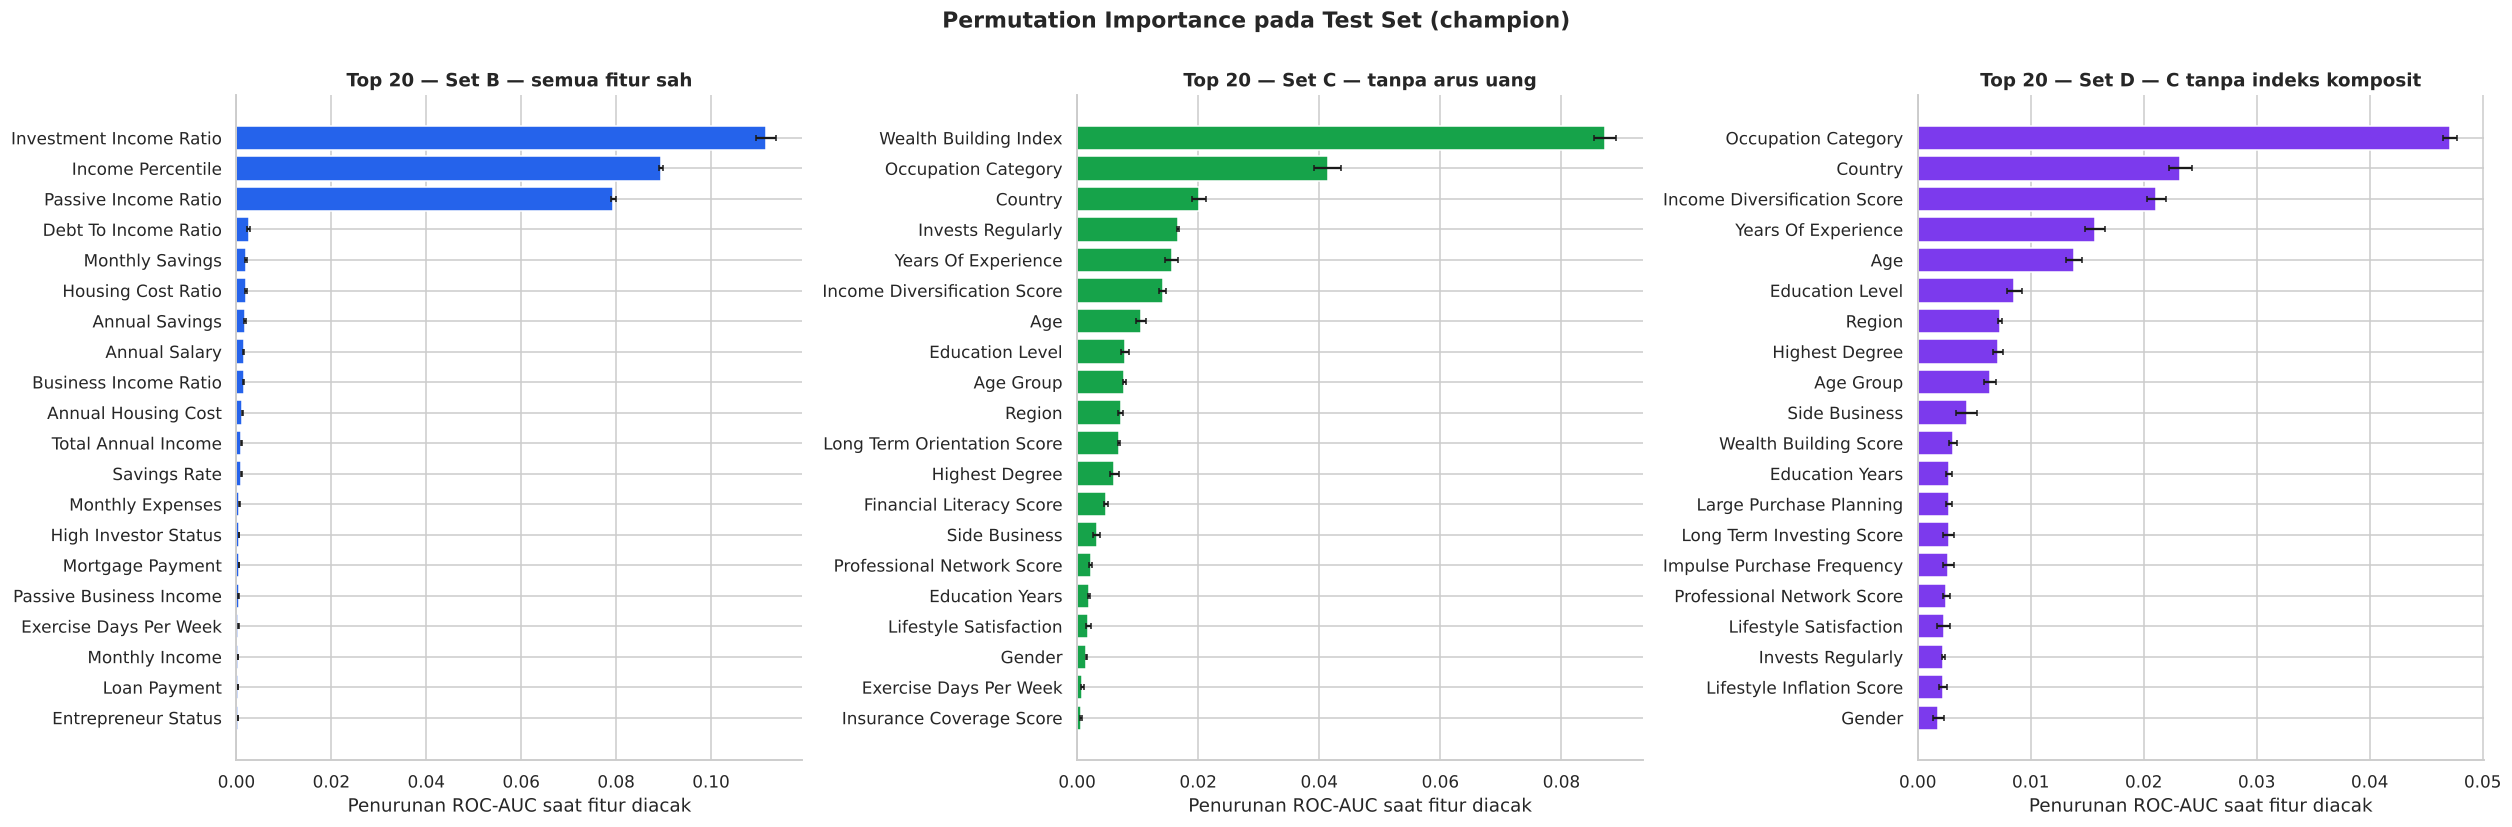

Top 5 Set B: investment_income_ratio, income_percentile, passive_income_ratio, debt_to_income_ratio, monthly_savings
Top 5 Set C: wealth_building_index, occupation_category, country, invests_regularly, years_of_experience
Top 5 Set D: occupation_category, country, income_diversification_score, years_of_experience, age


In [23]:
nice = lambda c: c.replace("_", " ").title()
fig, axes = plt.subplots(1, 3, figsize=(23, 7.5))
for ax, imp, ttl, col in [(axes[0], imp_B, "Set B — semua fitur sah", C["blue"]), (axes[1], imp_C, "Set C — tanpa arus uang", C["green"]), (axes[2], imp_D, "Set D — C tanpa indeks komposit", C["purple"])]:
    t = imp.head(20)[::-1]
    ax.barh([nice(c) for c in t.feature], t.auc_drop, xerr=t["std"], color=col, ecolor="k", capsize=2)
    ax.set_title(f"Top 20 — {ttl}"); ax.set_xlabel("Penurunan ROC-AUC saat fitur diacak")
fig.suptitle("Permutation Importance pada Test Set (champion)", fontweight="bold", y=1.0)
savefig("10_permutation_importance"); plt.show()
print("Top 5 Set B:", ", ".join(imp_B.feature.head(5)))
print("Top 5 Set C:", ", ".join(imp_C.feature.head(5)))
print("Top 5 Set D:", ", ".join(imp_D.feature.head(5)))

> ⚠️ **Catatan interpretasi.** Permutation importance mengukur *ketergantungan model*, **bukan hubungan sebab-akibat**. Fitur yang saling berkorelasi (misalnya `monthly_income`, `annual_salary`, `total_annual_income`) saling "berbagi" nilai penting, sehingga masing-masing tampak lebih kecil dari pengaruh gabungannya. Dataset ini juga **sintetis**, jadi pola yang ditemukan mencerminkan aturan pembangkit data, bukan tentu dunia nyata.

---
## 14. Fungsi Inferensi
Menerima profil individu (dictionary; kolom yang tidak diisi otomatis diimputasi seperti saat pelatihan) dan mengembalikan probabilitas serta klasifikasi.

In [24]:
def predict_millionaire(profile: dict, model=None, data=D, threshold=0.5):
    # Prediksi probabilitas jutawan dari satu profil. Kolom yang tidak diberikan -> NaN -> diimputasi pipeline.
    model = model or CHAMP_MODEL
    row = pd.DataFrame([{c: profile.get(c, np.nan) for c in data.cols}])
    for c in data.num: row[c] = pd.to_numeric(row[c], errors="coerce")
    x = torch.from_numpy(data.prep.transform(row).astype(np.float32))
    p = float(torch.sigmoid(predict_logits(model, x))[0])
    return {"probabilitas_jutawan": round(p, 4), "prediksi": "🌟 Jutawan" if p >= threshold else "🌱 Bukan jutawan", "threshold": threshold}

X_te_raw = df.iloc[idx_test]
for k in range(3):
    prof = X_te_raw.iloc[k][FEATURES_MAIN].to_dict()
    print(f"Sampel {k+1} (label asli = {int(X_te_raw.iloc[k][TARGET])}):", predict_millionaire(prof, threshold=THR))
print("Profil sebagian (hanya 3 kolom):", predict_millionaire({"savings_rate": 0.35, "financial_literacy_score": 80, "age": 45}, threshold=THR))

Sampel 1 (label asli = 0): {'probabilitas_jutawan': 0.0004, 'prediksi': '🌱 Bukan jutawan', 'threshold': 0.53}
Sampel 2 (label asli = 0): {'probabilitas_jutawan': 0.2545, 'prediksi': '🌱 Bukan jutawan', 'threshold': 0.53}
Sampel 3 (label asli = 1): {'probabilitas_jutawan': 1.0, 'prediksi': '🌟 Jutawan', 'threshold': 0.53}


Profil sebagian (hanya 3 kolom): {'probabilitas_jutawan': 0.0066, 'prediksi': '🌱 Bukan jutawan', 'threshold': 0.53}


---
## 15. Kesimpulan, Keterbatasan & Saran

Bagian kesimpulan di bawah **dihasilkan dari variabel hasil eksperimen** sehingga angkanya selalu sinkron dengan output di atas.

In [25]:
ch = final.loc[CH_NAME]; hgb = final.loc["Gradient Boosting (HistGB)"]; lr_ = final.loc["Logistic Regression"]
A_, B_, C_, D_ = abl.iloc[0], abl.iloc[1], abl.iloc[2], abl.iloc[3]
dflt = final.loc[CHAMPION]                       # champion dengan resep default (belum dituning)
t3 = lambda s: ", ".join(f"`{c}`" for c in s.feature.head(5))

# Ringkasan CV per arsitektur terhadap Baseline (dinamis)
cv_lines = []
for n in ARCHS:
    if n == "Baseline MLP": continue
    d_loss = (piv[n] - piv["Baseline MLP"]).mean(); wins = int((piv[n] < piv["Baseline MLP"]).sum())
    verdict = "lebih baik" if wins >= CV_FOLDS - 1 and d_loss < 0 else ("lebih buruk" if wins <= 1 and d_loss > 0 else "tidak konsisten")
    cv_lines.append(f"{n}: Δ val-loss {d_loss:+.4f} vs Baseline, menang di {wins}/{CV_FOLDS} fold → **{verdict}**")
cv_txt = "; ".join(cv_lines)
acc_rng = agg["accuracy"].max() - agg["accuracy"].min()
tune_gain = (ch.test_accuracy - dflt.test_accuracy) * 100

txt = f'''
### ✅ Temuan Utama
1. **Prediksi sangat akurat tanpa kebocoran neraca.** Champion (**{CHAMPION}**, hasil tuning) mencapai **akurasi {ch.test_accuracy*100:.2f}%**, F1 **{ch.test_f1:.4f}**, ROC-AUC **{ch.test_roc_auc:.4f}** pada 10.000 data *test* yang tidak dipakai memilih apa pun. Stabilitas antar-seed: akurasi {SEED_STATS.loc['mean','test_acc']*100:.2f}% ± {SEED_STATS.loc['std','test_acc']*100:.2f}%.
2. **Perbandingan arsitektur (5-fold CV).** Val-loss rata-rata: Baseline **{agg.loc['Baseline MLP','val_loss']:.4f}**, Deep Regularized MLP **{agg.loc['Deep Regularized MLP','val_loss']:.4f}**, Tabular ResNet **{agg.loc['Tabular ResNet','val_loss']:.4f}**. {cv_txt}. Selisih akurasi antar-arsitektur hanya **{acc_rng*100:.2f} poin** — jadi perbedaannya nyata pada log-loss, tetapi **kecil secara praktis**. Dengan aturan 1-SE, champion = **{CHAMPION}**.
3. **Tuning membantu.** Champion default → tuned: akurasi test {dflt.test_accuracy*100:.2f}% → {ch.test_accuracy*100:.2f}% ({tune_gain:+.2f} poin), test loss {dflt.test_loss:.4f} → {ch.test_loss:.4f}. *Catatan keadilan:* hanya champion yang dituning; pembanding lain memakai resep default.
4. **Deep learning vs baseline klasik.** Gradient Boosting: akurasi **{hgb.test_accuracy*100:.2f}%** (AUC {hgb.test_roc_auc:.4f}); Logistic Regression: **{lr_.test_accuracy*100:.2f}%** (AUC {lr_.test_roc_auc:.4f}); champion NN: **{ch.test_accuracy*100:.2f}%** (AUC {ch.test_roc_auc:.4f}). {"Gradient Boosting setara/lebih baik dari neural network pada data tabular ini — manfaat deep learning di sini terbatas." if hgb.test_accuracy >= ch.test_accuracy - 0.003 else "Neural network unggul jelas dari baseline klasik."}
5. **Dampak leakage terukur.** Set A (komponen neraca dipakai): akurasi **{A_.test_acc*100:.2f}%** vs Set B (bersih): **{B_.test_acc*100:.2f}%** — selisih **{(A_.test_acc-B_.test_acc)*100:+.2f} poin** (AUC {A_.test_auc:.4f} vs {B_.test_auc:.4f}). Selisihnya terlihat modest karena arus uang (pendapatan, rasio investasi) sudah sangat informatif, tetapi komponen neraca tetap tidak sah dipakai: ia memuat kekayaan yang menjadi definisi target.
6. **Tanpa arus uang, prediksi turun tajam namun tetap bermakna.** Set C (kebiasaan + psikologi + karier + demografi): akurasi **{C_.test_acc*100:.2f}%** (AUC {C_.test_auc:.4f}); Set D (tanpa indeks komposit): **{D_.test_acc*100:.2f}%** (AUC {D_.test_auc:.4f}). Pembanding: menebak kelas mayoritas = 57,5%. Artinya **nominal uang (pendapatan, tabungan, rasio investasi) jauh lebih menentukan daripada kebiasaan murni**.
7. **Overfitting.** Bobot terbaik di-*restore* dari epoch dengan val-loss terendah. Gap akurasi train–val pada epoch terbaik: Baseline {gap.loc['Baseline MLP','Gap acc (train−val)']*100:+.2f} poin, Deep MLP {gap.loc['Deep Regularized MLP','Gap acc (train−val)']*100:+.2f}, ResNet {gap.loc['Tabular ResNet','Gap acc (train−val)']*100:+.2f}. Model cepat menghafal data latih (akurasi train → ~99%), sehingga early stopping sangat penting.

### 🔑 Faktor yang Paling Menentukan (permutation importance, 5 teratas)
- **Set B (semua fitur sah):** {t3(imp_B)}
- **Set C (tanpa arus uang):** {t3(imp_C)}
- **Set D (tanpa arus uang & indeks komposit):** {t3(imp_D)}
'''
display(Markdown(txt))


### ✅ Temuan Utama
1. **Prediksi sangat akurat tanpa kebocoran neraca.** Champion (**Tabular ResNet**, hasil tuning) mencapai **akurasi 97.15%**, F1 **0.9665**, ROC-AUC **0.9972** pada 10.000 data *test* yang tidak dipakai memilih apa pun. Stabilitas antar-seed: akurasi 97.07% ± 0.13%.
2. **Perbandingan arsitektur (5-fold CV).** Val-loss rata-rata: Baseline **0.0891**, Deep Regularized MLP **0.0929**, Tabular ResNet **0.0844**. Deep Regularized MLP: Δ val-loss +0.0038 vs Baseline, menang di 0/5 fold → **lebih buruk**; Tabular ResNet: Δ val-loss -0.0047 vs Baseline, menang di 5/5 fold → **lebih baik**. Selisih akurasi antar-arsitektur hanya **0.28 poin** — jadi perbedaannya nyata pada log-loss, tetapi **kecil secara praktis**. Dengan aturan 1-SE, champion = **Tabular ResNet**.
3. **Tuning membantu.** Champion default → tuned: akurasi test 96.44% → 97.15% (+0.71 poin), test loss 0.0804 → 0.0675. *Catatan keadilan:* hanya champion yang dituning; pembanding lain memakai resep default.
4. **Deep learning vs baseline klasik.** Gradient Boosting: akurasi **97.21%** (AUC 0.9974); Logistic Regression: **95.18%** (AUC 0.9906); champion NN: **97.15%** (AUC 0.9972). Gradient Boosting setara/lebih baik dari neural network pada data tabular ini — manfaat deep learning di sini terbatas.
5. **Dampak leakage terukur.** Set A (komponen neraca dipakai): akurasi **98.69%** vs Set B (bersih): **97.15%** — selisih **+1.54 poin** (AUC 0.9994 vs 0.9972). Selisihnya terlihat modest karena arus uang (pendapatan, rasio investasi) sudah sangat informatif, tetapi komponen neraca tetap tidak sah dipakai: ia memuat kekayaan yang menjadi definisi target.
6. **Tanpa arus uang, prediksi turun tajam namun tetap bermakna.** Set C (kebiasaan + psikologi + karier + demografi): akurasi **76.88%** (AUC 0.8442); Set D (tanpa indeks komposit): **74.45%** (AUC 0.8181). Pembanding: menebak kelas mayoritas = 57,5%. Artinya **nominal uang (pendapatan, tabungan, rasio investasi) jauh lebih menentukan daripada kebiasaan murni**.
7. **Overfitting.** Bobot terbaik di-*restore* dari epoch dengan val-loss terendah. Gap akurasi train–val pada epoch terbaik: Baseline +2.74 poin, Deep MLP +3.32, ResNet +1.59. Model cepat menghafal data latih (akurasi train → ~99%), sehingga early stopping sangat penting.

### 🔑 Faktor yang Paling Menentukan (permutation importance, 5 teratas)
- **Set B (semua fitur sah):** `investment_income_ratio`, `income_percentile`, `passive_income_ratio`, `debt_to_income_ratio`, `monthly_savings`
- **Set C (tanpa arus uang):** `wealth_building_index`, `occupation_category`, `country`, `invests_regularly`, `years_of_experience`
- **Set D (tanpa arus uang & indeks komposit):** `occupation_category`, `country`, `income_diversification_score`, `years_of_experience`, `age`


### ⚠️ Keterbatasan
- **Data sintetis** — pola dibentuk oleh aturan pembangkit data; temuan tidak otomatis berlaku pada populasi nyata.
- **Hubungan bukan kausal** — "tabungan tinggi berkaitan dengan status jutawan" tidak berarti menabung *menyebabkan* kekayaan (bisa sebaliknya: orang kaya mampu menabung lebih banyak).
- **Fitur arus uang (Set B) tetap sangat dekat dengan hasil akhir** (pendapatan tinggi → kekayaan tinggi). Set C/D disediakan sebagai batas bawah.
- **Set C/D bukan "kebiasaan murni"**: masih memuat demografi & karier (`country`, `occupation_category`, `age`) yang bukan kebiasaan yang bisa diubah seseorang. Interpretasikan sebagai *perilaku + latar belakang*.
- **Total aset tidak sepenuhnya dapat direkonstruksi** dari 11 komponen yang tersedia, sehingga ukuran leakage pada ablation Set A adalah *perkiraan*, bukan batas atas.
- **Satu split tetap** untuk tuning dan evaluasi akhir; CV dan uji multi-seed mengurangi (bukan menghilangkan) ketergantungan pada satu pembagian data. *Early stopping* pada fold validasi CV membuat skor CV sedikit optimistis, namun efeknya setara untuk semua arsitektur.
- Imputasi median untuk kolom yang kosong secara struktural (mis. `business_failure_count` bagi non-pengusaha) menyembunyikan informasi "tidak berlaku".

### 🚀 Saran Pengembangan
1. Tambahkan *missing indicator* untuk kolom yang kosong secara struktural.
2. Coba model tabular lain (TabNet, FT-Transformer) atau *ensembling* NN + Gradient Boosting.
3. Gunakan SHAP untuk penjelasan per individu & interaksi antar fitur.
4. Lakukan kalibrasi probabilitas (Platt/isotonic) bila probabilitas dipakai untuk pengambilan keputusan.
5. Uji pada **regresi `net_worth`** (log) sebagai pelengkap klasifikasi biner.

---
### 💾 Menyimpan Artefak
Model champion, preprocessor, dan konfigurasi disimpan agar eksperimen dapat dipakai ulang tanpa melatih ulang.

In [26]:
torch.save({"state_dict": CHAMP_MODEL.state_dict(), "arch": CHAMPION, "kwargs": {**DEFAULT_KW[CHAMPION], **BEST_KW}, "input_dim": D.dim},
           OUT_DIR / "champion_model.pt")
joblib.dump({"preprocessor": D.prep, "feature_cols": FEATURES_MAIN, "num_cols": D.num, "cat_cols": D.cat}, OUT_DIR / "preprocessor_setB.joblib")
json.dump({"champion": CHAMPION, "lr": BEST_OPT_LR, "weight_decay": BEST_WD, "optimizer": BEST_OPT, "capacity": {k: (v if not isinstance(v, np.generic) else v.item()) for k, v in BEST_KW.items()},
           "threshold_f1_val": THR, "seed": SEED, "split": "80/10/10 stratified", "n_features_set_B": len(FEATURES_MAIN)},
          open(OUT_DIR / "config_final.json", "w"), indent=2)
print("Tersimpan di folder 'outputs/':", sorted(p.name for p in OUT_DIR.iterdir()))
print("Gambar di folder 'figures/'   :", sorted(p.name for p in FIG_DIR.iterdir()))

Tersimpan di folder 'outputs/': ['champion_model.pt', 'config_final.json', 'cv_results_per_fold.csv', 'final_test_results.csv', 'permutation_importance_setB.csv', 'permutation_importance_setC.csv', 'permutation_importance_setD.csv', 'preprocessor_setB.joblib']
Gambar di folder 'figures/'   : ['01_target_dan_missing.png', '02_distribusi_fitur.png', '03_audit_leakage.png', '04_cv_benchmark.png', '05_tuning.png', '06_ablation_fitur.png', '07_kurva_belajar.png', '08_cm_roc_pr.png', '09_kalibrasi_threshold.png', '10_permutation_importance.png']


---
## 16. Repositori & Referensi

**Repositori kode:** `https://github.com/[username]/[nama-repo]` *(isi dengan URL repositori kelompok)*

**Referensi**
1. Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press.
2. Gorishniy, Y., Rubachev, I., Khrulkov, V., & Babenko, A. (2021). *Revisiting Deep Learning Models for Tabular Data*. NeurIPS 2021.
3. He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition*. CVPR.
4. Ioffe, S., & Szegedy, C. (2015). *Batch Normalization*. ICML.
5. Srivastava, N., dkk. (2014). *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*. JMLR 15(1).
6. Loshchilov, I., & Hutter, F. (2019). *Decoupled Weight Decay Regularization (AdamW)*. ICLR.
7. Breiman, L. (2001). *Random Forests* (permutation importance). Machine Learning, 45(1).
8. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (aturan satu-standar-error), Springer.
9. Afiahayati. (2026). *Slide Perkuliahan Pembelajaran Mesin Mendalam*. FMIPA UGM.